# Big Data & Data Mining: Road Accident Analysis (STATS19, 2019)
**Module:** 771762 Big Data and Data Mining · **Author:** Michelle Buchi Okonicha 202610063

## Overview
This notebook analyses UK road traffic accidents from the DfT STATS19 open
dataset (`accident_data_v1.0.0_2023.db`) to advise the Department for Transport
on road-safety policy. It addresses five tasks: temporal accident patterns
(Q1), severity drivers via association rule mining and a severity classifier
(Q2), spatial clustering of the Humberside region (Q3), weekly accident
forecasting for three police forces (Q4), and daily forecasting for Hull's
highest-incident areas (Q5).

This analysis evaluates whether adverse conditions and urban
density drive accident *frequency*, while rural high-speed roads drive
*severity*; and predictability declines sharply as the analysis zooms from
force-level down to the LSOA-day.

## Data
- **Source:** DfT Road Safety Open Dataset (STATS19), 2017-2020, four tables
  (`accident`, `casualty`, `vehicle`, `lsoa`).
- **Focus year:** 2019 (a complete, pre-pandemic sample); 2017-2018 used as
  training history for forecasting (Q4/Q5).
- Missing values are encoded as `-1`. Three distinct cases are separated and
  handled differently: fields where `-1` means *not applicable* (e.g.
  `junction_control`) are left alone; fields where it means *unknown* and the
  value is recoverable from the rest of the record (`speed_limit`,
  `road_surface_conditions`) are imputed and the imputer is validated
  (Section 2.1); and `lsoa_of_accident_location`, which stores the sentinel as
  the *string* `"-1"`, is normalised to NaN at load.

## Reproducibility
1. Place the course database accident_data_v1.0.0_2023.db in the same folder as this notebook (or edit DB_PATH in Section 0).
2. Run cells top-to-bottom (Kernel -> Restart & Run All).
3. Requires: `pandas`, `numpy`, `scipy`, `scikit-learn`, `statsmodels`,
   `mlxtend`, `matplotlib`. Exact versions are printed by the environment
   fingerprint below. A single global `SEED = 42` controls every stochastic
   routine (imputation hold-out, clustering, train/test splits, model fitting),
   so the notebook is deterministic from one point of control.

## Contents
- **Section 0**: Environment setup & database helpers
- **Section 1**: Schema inspection & data audit
- **Section 2**: Cleaning, validated imputation & preparation
- **Section 3**: Q1: Temporal patterns (hour/day, motorcycles, pedestrians)
- **Section 4**: Q2: Association rule mining on severity (Apriori) & severity prediction
- **Section 5**: Q3: Spatial clustering of the Humberside region
- **Section 6**: Q4: Weekly accident forecasting by police force
- **Section 7**: Q5: Daily forecasting for Hull's highest-incident LSOAs
- **Section 8**: Conclusions & limitations
- **Section 9**: Recommendations to the Department for Transport


## Section 0: Environment Setup and Database Helpers

Imports, the global random seed, display configuration, the database path, and the cached read-only connection used by every query in this notebook.

In [1]:
#imported packages and libraries
import itertools
import sqlite3
import time
import warnings
from pathlib import Path
from typing import Optional, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

from scipy.stats import chi2_contingency, chisquare
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, roc_auc_score, average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

# One global seed so it can be used everywhere for imputation,  K-Means, DBSCAN, train/test splits and model fitting.
SEED = 42

In [2]:
# Environment fingerprint (this is to help with reproducibility).
import sys, sklearn, scipy, statsmodels, mlxtend, matplotlib
print(f"Python      {sys.version.split()[0]}")
for m in (pd, np, scipy, sklearn, statsmodels, mlxtend, matplotlib):
    print(f"{m.__name__:<12} {m.__version__}")

Python      3.9.6
pandas       2.3.3
numpy        1.26.4
scipy        1.13.1
sklearn      1.6.1
statsmodels  0.14.6
mlxtend      0.23.4
matplotlib   3.9.4


Widen the pandas display limits so that full tables are visible during the schema audit rather than being elided.

In [3]:
# Displaying configuration and table contents

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 120)

Configure the database path and define the constants used throughout the notebook.

In [4]:
# Configure the accident database path so it is usable elsewhere
DB_PATH = Path("accident_data_v1.0.0_2023.db")

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"Database not found next to the notebook: {DB_PATH.name}\n"
        "Place accident_data_v1.0.0_2023.db in the notebook's folder, "
        "or update DB_PATH to point to it."
    )
# Print only the filename, not the resolved absolute path, so the output
# does not depend on (or expose) the machine the notebook was run on.
print(f"Using database: {DB_PATH.name}")

Using database: accident_data_v1.0.0_2023.db


Open one read-only SQLite connection and wrap every query in a single helper, so no cell reopens the file or mutates the source database.

In [5]:
# One read-only connection opened once and reused to prevent mutating the DfT database.
_CONN = None  # module-level cache

def get_connection(db_path: Path = DB_PATH) -> sqlite3.Connection:
    """Return a cached, read-only SQLite connection (opened once, reused)."""
    global _CONN
    if _CONN is None:
        # mode=ro guarantees the analysis cannot alter the source database.
        _CONN = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    return _CONN

def run_query(sql: str, params: Optional[tuple] = None) -> pd.DataFrame:
    """Run a read-only SQL query and return a DataFrame.

    On failure, re-raise as RuntimeError carrying the offending SQL and the
    underlying error (e.g. bad column name, malformed SQL) for fast debugging.
    """
    try:
        return pd.read_sql_query(sql, get_connection(), params=params)
    except Exception as exc:
        raise RuntimeError(f"Query failed:\n{sql}\n\n{exc}") from exc


## Section 1: Schema Inspection and Data Auditing
Before cleaning the data, we first need to map all the tables and their columns
and also their types and row counts. This drives the downstream decisions in this
accident database for motorcycle capacity fields, `police_force`, LSOA codes, and
how the missing values are encoded.

First, list the tables and their row counts.

In [6]:
# Creating a tables variable to see all the tables and their row counts

tables = run_query(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;"
)["name"].tolist()

print(f"Tables found are {len(tables)}:\n")
for t in tables:
    n = run_query(f'SELECT COUNT(*) AS n FROM "{t}";')["n"].iloc[0]
    print(f"  {t:<35} {n:>10,} rows")

Tables found are 4:

  accident                               461,352 rows
  casualty                               600,332 rows
  lsoa                                    34,378 rows
  vehicle                                849,091 rows


Next, read the column schema of each table.

In [7]:
# Here, finding the column names and the declared types for each table using the PRAGMA table info.
for t in tables:
    info = run_query(f'PRAGMA table_info("{t}");')[["name", "type"]]
    print(f"\n The {t} table ")
    print(info.to_string(index=False))


 The accident table 
                                       name type
                             accident_index     
                              accident_year     
                         accident_reference     
                      location_easting_osgr     
                     location_northing_osgr     
                                  longitude     
                                   latitude     
                               police_force     
                          accident_severity     
                         number_of_vehicles     
                       number_of_casualties     
                                       date     
                                day_of_week     
                                       time     
                   local_authority_district     
               local_authority_ons_district     
                    local_authority_highway     
                           first_road_class     
                          first_road_number    

### Section 1.1: Auditing the data

Before cleaning, inspect the formats, value distributions and missing-value encodings, so that later decisions about what to impute, parse, filter or categorise are driven by what the data actually contain.

Sample the accident table and check the inferred dtypes.

In [8]:
# viewing the different columns and their types in the accident table
accident_sample = run_query("SELECT * FROM accident LIMIT 5;")
print("Inferred dtypes:\n", accident_sample.dtypes, "\n")

Inferred dtypes:
 accident_index                                  object
accident_year                                    int64
accident_reference                              object
location_easting_osgr                          float64
location_northing_osgr                         float64
longitude                                      float64
latitude                                       float64
police_force                                     int64
accident_severity                                int64
number_of_vehicles                               int64
number_of_casualties                             int64
date                                            object
day_of_week                                      int64
time                                            object
local_authority_district                         int64
local_authority_ons_district                    object
local_authority_highway                         object
first_road_class                               

Check which accident years the database covers.

In [9]:
# running and counting the accident and viewing the accident year 
run_query("""
    SELECT accident_year, COUNT(*) AS n
    FROM accident
    GROUP BY accident_year
    ORDER BY accident_year;
    """)

,accident_year,n
0,2017,129982
1,2018,122635
2,2019,117536
3,2020,91199


Inspect the value distributions and locate the missing-value sentinels.

In [10]:
#the specific required columns to tell their details
for col in ["accident_severity", "day_of_week", "speed_limit",
            "light_conditions", "weather_conditions",
            "road_surface_conditions", "urban_or_rural_area"]:
    vc = run_query(
        f'SELECT "{col}", COUNT(*) AS n FROM accident '
        f'GROUP BY "{col}" ORDER BY n DESC LIMIT 15;'
    )
    print(f"\nThe {col}:")
    print(vc.to_string(index=False))


The accident_severity:
 accident_severity      n
                 3 368297
                 2  86659
                 1   6396

The day_of_week:
 day_of_week     n
           6 75211
           5 70482
           4 69055
           3 68297
           2 65091
           7 61188
           1 52028

The speed_limit:
 speed_limit      n
          30 274613
          60  58032
          20  43224
          40  38732
          70  27822
          50  18837
          -1     92

The light_conditions:
 light_conditions      n
                1 329082
                4  95026
                6  23725
                7  10154
                5   3362
               -1      3

The weather_conditions:
 weather_conditions      n
                  1 366976
                  2  53966
                  9  14115
                  8  10949
                  5   5474
                  4   5006
                  3   2254
                  7   1977
                  6    614
                 -1     21

The

Check how dates and times are stored, so they can be parsed correctly.

In [11]:
# Here, we look through the date, time and day_of_week columns in the accident table to see the format
run_query("SELECT date, time, day_of_week FROM accident LIMIT 10;")

,date,time,day_of_week
0,05/08/2017,03:12,7
1,01/01/2017,01:30,1
2,01/01/2017,00:30,1
3,01/01/2017,01:11,1
4,01/01/2017,01:42,1
5,01/01/2017,03:31,1
6,01/01/2017,04:07,1
7,01/01/2017,05:20,1
8,01/01/2017,03:18,1
9,01/01/2017,03:00,1


List the police forces, to locate Humberside.

In [12]:
# checking the police force column in the accident table
run_query("""
    SELECT police_force, COUNT(*) AS n
    FROM accident
    GROUP BY police_force
    ORDER BY CAST(police_force AS INTEGER);
""")

,police_force,n
0,1,98098
1,3,4315
2,4,12037
3,5,8394
4,6,13852
5,7,7331
6,10,8688
7,11,3451
8,12,6032
9,13,14886


Inspect the vehicle table's type and engine-capacity coding.

In [13]:
# Finding both the vehicle type and the engine capacity
vehicle_category = run_query(
    "SELECT vehicle_type, COUNT(*) AS n FROM vehicle "
    "GROUP BY vehicle_type ORDER BY CAST(vehicle_type AS INTEGER)"
).to_string(index=False)

vehicle_engine_capacity = run_query("""
    SELECT MIN(CAST(engine_capacity_cc AS INTEGER)) AS min_cc,
           MAX(CAST(engine_capacity_cc AS INTEGER)) AS max_cc
    FROM vehicle;
""")


print("- vehicle_type -")
print(vehicle_category)
print("\n- engine_capacity_cc summary -")
print(vehicle_engine_capacity)

- vehicle_type -
 vehicle_type      n
           -1    791
            1  71282
            2   6111
            3  31814
            4   8426
            5  20950
            8  17864
            9 594606
           10   1492
           11  15626
           16    321
           17   1855
           18     76
           19  47458
           20   4072
           21  13555
           22    924
           23    261
           90   5458
           97   1598
           98   4459
           99     92

- engine_capacity_cc summary -
   min_cc  max_cc
0      -1   99999


Identify the district codes for Hull, Humberside and the East Riding.

In [14]:
# Selecting the local authority district count to find the different regions
run_query("""
    SELECT local_authority_district, COUNT(*) AS n
    FROM accident
    GROUP BY local_authority_district
    ORDER BY n DESC
    LIMIT 25;

    """)

,local_authority_district,n
0,300,9762
1,1,5746
2,204,5707
3,9,4874
4,596,4320
5,5,4281
6,8,4234
7,10,3862
8,30,3833
9,27,3794


## Section 2: Cleaning, Imputation and Data Preparation

Prepare the accident data for every downstream task: audit the missing values, separate *not applicable* from *unknown*, impute what is recoverable (with the imputer validated before use), normalise the LSOA sentinel, and confirm the regional codes against geography.

From the audit above: severity 1 = Fatal, 2 = Serious, 3 = Slight.

In [15]:
# STATS19 code definitions & analysis constants. -1 = "Data missing or out of range".

# Severity & time
SEVERITY = {1: "Fatal", 2: "Serious", 3: "Slight"}

# Confirmed empirically: 01/01/2017 (Sunday) -> 1, 05/08/2017 (Saturday) -> 7.
DAY_OF_WEEK = {1: "Sunday", 2: "Monday", 3: "Tuesday", 4: "Wednesday",
               5: "Thursday", 6: "Friday", 7: "Saturday"}

# Motorcycle capacity bands (Q1). Band labels are declared once and consumed by
# both the vehicle_type map and the engine-cc fallback, so they cannot diverge.
BAND_125   = "<=125cc"
BAND_MID   = "125-500cc"
BAND_LARGE = ">500cc"
BAND_ORDER = [BAND_125, BAND_MID, BAND_LARGE]

# vehicle_type of band (2 = moped/<=50cc, 3 = <=125cc; 4 = 125-500cc; 5 = >500cc)
MOTORCYCLE_BANDS = {2: BAND_125, 3: BAND_125, 4: BAND_MID, 5: BAND_LARGE}

# 97 = "Motorcycle - unknown cc": queried so we can attempt cc-based recovery.
MOTORCYCLE_UNKNOWN_TYPE = 97

# 23 = "Electric motorcycle": a motorcycle, but engine_capacity_cc has no meaning for it, so it cannot be 
# assigned to a cc band on any principled basis. Excluded explicitly and counted below rather than dropped silently.
MOTORCYCLE_ELECTRIC_TYPE = 23

# Every vehicle_type pulled for the motorcycle analysis.
MOTORCYCLE_TYPES = tuple(MOTORCYCLE_BANDS) + (MOTORCYCLE_UNKNOWN_TYPE,
                                              MOTORCYCLE_ELECTRIC_TYPE)

# Region of interest (Q3/Q4/Q5).
# Legacy numeric local_authority_district codes proved unreliable, so ONS codes
# are used instead, cross-checked against police force 16.
HUMBERSIDE_FORCE = 16
REGION_ONS = {
    "E06000010": "Kingston upon Hull",
    "E06000011": "East Riding of Yorkshire",
    "E06000012": "North East Lincolnshire",
    "E06000013": "North Lincolnshire",
}
HULL_ONS = "E06000010"
EAST_RIDING_ONS = "E06000011"

# Missing-value sentinel.
MISSING = -1

# Ordered weekday labels (Mon-Sun) and per-band colours, reused across all plots.
DAY_ORDER   = ["Monday", "Tuesday", "Wednesday", "Thursday",
               "Friday", "Saturday", "Sunday"]
BAND_COLORS = {BAND_125: "#31708E", BAND_MID: "#C08552", BAND_LARGE: "#8B3A3A"}


Load the accident table and derive the temporal features used throughout.

The location field `lsoa_of_accident_location` stores its missing-value sentinel as the string `"-1"`, so a numeric `== -1` test never catches it; left as-is it would behave as a genuine LSOA, counted by `value_counts()` and able to enter the Q5 top-30 as a phantom high-incident area. It is normalised to `NaN` once, at the point of load, so every downstream `.notna()` filter and the missing-value audit both see it.

In [16]:
# Load the accident table once, parse its datetime, and normalise the sentinel
# codes that SQLite hands back as TEXT rather than as integers.
def load_accidents() -> pd.DataFrame:
    """Load the accident table with parsed datetime and temporal features."""
    df = run_query("SELECT * FROM accident;")

# Combine the separate date and time columns into a single timestamp. errors="coerce" turns any
# unparseable row into NaT rather than aborting the load.
    dt = pd.to_datetime(
        df["date"].str.strip() + " " + df["time"].str.strip(),
        format="%d/%m/%Y %H:%M", errors="coerce",
    )
    n_bad = int(dt.isna().sum())
    if n_bad:
        print(f"Warning: {n_bad:,} rows had unparseable date/time (set to NaT).")

    # Normalise the "-1" string LSOA sentinel to NaN at load (see note above).
    lsoa = df["lsoa_of_accident_location"].astype("string").str.strip()
    valid = lsoa.str.fullmatch(r"[EWS]01\d{6}")   # E/W/S + 01 + 6 digits
    n_bad_lsoa = int((~valid.fillna(False)).sum())
    df["lsoa_of_accident_location"] = lsoa.where(valid.fillna(False))
    print(f"LSOA codes: {n_bad_lsoa:,} of {len(df):,} non-conforming "
          f"(sentinel/blank) which is set to NaN "
          f"({df['lsoa_of_accident_location'].notna().mean():.1%} usable).")

    df["datetime"]       = dt
    df["date_parsed"]    = dt.dt.normalize()
    df["hour"]           = dt.dt.hour
    df["month"]          = dt.dt.month
    df["day_name"]       = df["day_of_week"].map(DAY_OF_WEEK)
    df["severity_label"] = df["accident_severity"].map(SEVERITY)
    return df

accidents = load_accidents()

# Assumptions made throughout

EXPECTED_YEARS = {2017, 2018, 2019, 2020}
MIN_ROWS = 400_000

assert len(accidents) >= MIN_ROWS, (
    f"Only {len(accidents):,} accidents loaded; expected at least "
    f"{MIN_ROWS:,}. Check that DB_PATH points at the full 2017-2020 database.")
assert set(accidents["accident_year"].unique()) == EXPECTED_YEARS, (
    f"Years present are {sorted(accidents['accident_year'].unique())}; "
    f"expected {sorted(EXPECTED_YEARS)}. Q4/Q5 assume 2017-2018 history and "
    "a complete 2019.")
assert accidents["accident_index"].is_unique, (
    "accident_index is not unique; the accident table has duplicate rows and "
    "every count in this notebook would be inflated.")
assert accidents["datetime"].notna().mean() > 0.99, (
    f"Only {accidents['datetime'].notna().mean():.1%} of rows have a parseable "
    "datetime; the temporal analysis in Q1 and the forecasting in Q4/Q5 would "
    "silently drop the rest.")

print(f"\nLoaded {len(accidents):,} accidents "
      f"({accidents['accident_year'].min()}-{accidents['accident_year'].max()}); "
      "integrity checks passed.")
accidents[["accident_index", "datetime", "hour", "day_name",
           "severity_label", "police_force", "local_authority_district"]].head()


LSOA codes: 23,141 of 461,352 non-conforming (sentinel/blank) which is set to NaN (95.0% usable).

Loaded 461,352 accidents (2017-2020); integrity checks passed.


,accident_index,datetime,hour,day_name,severity_label,police_force,local_authority_district
0,2017010001708,2017-08-05 03:12:00,3,Saturday,Fatal,1,32
1,2017010009342,2017-01-01 01:30:00,1,Sunday,Slight,1,1
2,2017010009344,2017-01-01 00:30:00,0,Sunday,Slight,1,5
3,2017010009348,2017-01-01 01:11:00,1,Sunday,Slight,1,32
4,2017010009350,2017-01-01 01:42:00,1,Sunday,Serious,1,4


Profile missing values: both true NaN and the STATS19 `-1` sentinel.

In [17]:
# Missing data appears two ways here: as NaN and as the STATS19 -1 code.
def missing_report(df: pd.DataFrame, sentinel: int = MISSING) -> pd.DataFrame:
    """Report NaN and sentinel (-1) counts/percentages per column.

   Object-dtype columns are compared as text, so a sentinel stored as the string "-1" is
   caught rather than being treated as complete; numeric columns are compared
   numerically so a float -1.0 also matches.
    """
    n = len(df)
    rows = []
    for col in df.columns:
        nan_n = int(df[col].isna().sum())
        if df[col].dtype == "O" or pd.api.types.is_string_dtype(df[col]):
            sent_n = int((df[col].astype("string").str.strip()
                          == str(sentinel)).sum())
        else:
            sent_n = int((df[col] == sentinel).sum())
        if nan_n or sent_n:
            rows.append({"column": col,
                         "nan": nan_n, "nan_%": round(100 * nan_n / n, 2),
                         "sentinel(-1)": sent_n,
                         "sentinel_%": round(100 * sent_n / n, 2)})
    return (pd.DataFrame(rows)
            .sort_values(["sentinel(-1)", "nan"], ascending=False)
            .reset_index(drop=True))

missing_report(accidents)


,column,nan,nan_%,sentinel(-1),sentinel_%
0,junction_control,0,0.00,194556,42.17
1,second_road_number,0,0.00,193804,42.01
2,second_road_class,0,0.00,155838,33.78
3,trunk_road_flag,0,0.00,39030,8.46
4,local_authority_highway,0,0.00,2294,0.50
5,road_surface_conditions,0,0.00,1023,0.22
6,local_authority_district,0,0.00,991,0.21
7,special_conditions_at_site,0,0.00,713,0.15
8,carriageway_hazards,0,0.00,644,0.14
9,pedestrian_crossing_human_control,0,0.00,564,0.12


**Where the missing LSOA codes come from.** 23,141 of the 461,352 records (5.0%)
carry a non-conforming LSOA, and that gap has two distinct causes which need
separating before either can be treated.

The larger part is *structural*. A block of police forces records no LSOA on any
accident at all, not occasionally, never. That is not a data-quality failure but
a different statistical geography: LSOAs cover England and Wales, and Scotland
uses Data Zones instead, so there is no LSOA for these forces to record. The cell
below tests that explanation rather than asserting it, by checking whether those
forces' accidents actually sit north of the border. The remainder is *sporadic*
ordinary missingness scattered thinly across forces that normally do record an
LSOA.

The distinction decides the treatment. Imputing a structural absence would mean
inventing an English geography for Scottish accidents; there is nothing to
recover, so exclusion is the only defensible option. And this is why the
sentinel matters more than its 5% share suggests: it is not noise, it is an
entire nation absent from one column, and any LSOA-keyed analysis that reads
`"-1"` as a valid area silently aggregates every Scottish accident into one
phantom "area". Q5 is England-only and unaffected, but that is established
below, not assumed.


**Why the gap is partitioned by volume, not presence.** Asking only whether a force appears in both the complete and incomplete groups cannot tell apart two different failures: a force filing one bad record among twenty thousand good ones, and a force that never files an LSOA at all. Presence collapses both to "sporadic" the moment a single record goes either way, so the two are counted separately below.

In [18]:
# Where do the non-conforming LSOA codes come from?
no_lsoa = accidents["lsoa_of_accident_location"].isna()

f_missing = {int(x) for x in accidents.loc[no_lsoa, "police_force"].unique()}
f_present = {int(x) for x in accidents.loc[~no_lsoa, "police_force"].unique()}
never_records = sorted(f_missing - f_present)      # forces with NO valid LSOA, ever

# Partition the gap by volume and not by presence (see note above).
in_never  = accidents["police_force"].isin(never_records)
structural = no_lsoa & in_never
sporadic   = no_lsoa & ~in_never
n_gap = int(no_lsoa.sum())

print(f"Records without a valid LSOA: {n_gap:,} ({no_lsoa.mean():.1%} of the table)\n")
print(f"  STRUCTURAL - forces that never record one : {int(structural.sum()):,} "
      f"({structural.sum() / n_gap:.1%} of the gap)")
print(f"    forces: {never_records}")
print(f"  SPORADIC  - forces that usually do record : {int(sporadic.sum()):,} "
      f"({sporadic.sum() / n_gap:.1%} of the gap)")

# How bad is the sporadic residual within any single force?
spor_rate = (accidents[~in_never].groupby("police_force")
             ["lsoa_of_accident_location"].apply(lambda s: s.isna().mean()))
print(f"    across {int(accidents.loc[sporadic, 'police_force'].nunique())} forces; "
      f"worst per-force rate {spor_rate.max():.2%} "
      f"(force {int(spor_rate.idxmax())}), median {spor_rate.median():.2%}")

# LSOAs are an England and Wales geography, so if these forces are Scottish their accidents
# should sit north of the border rather than being scattered through the country.

lat_never = accidents.loc[in_never, "latitude"].dropna()
lat_other = accidents.loc[~in_never, "latitude"].dropna()
north_share = float((lat_never > 55).mean()) if len(lat_never) else float("nan")
print(f"\n  Geographic check on the never-recording forces:")
if len(lat_never):
    print(f"    median latitude, never-record forces : {lat_never.median():.2f} N")
    print(f"    median latitude, all other forces    : {lat_other.median():.2f} N")
    print(f"    share of never-record rows above 55 N: {north_share:.1%}")
else:
    print("    (no never-recording forces in this dataset - check not applicable)")

dominant = "STRUCTURAL" if structural.sum() > sporadic.sum() else "SPORADIC"
share = max(structural.sum(), sporadic.sum()) / n_gap
print(f"\n The gap is predominantly {dominant} ({share:.1%}).")
if dominant == "STRUCTURAL" and north_share > 0.9:
    print("   These forces are not failing to fill a field: they sit north of the")
    print("   border and record a different statistical geography (Scotland uses")
    print("   Data Zones, not LSOAs). There is no LSOA to recover, so imputation is")
    print("   meaningless and exclusion is the only correct treatment. The sporadic")
    print("   residual is a small enough share to exclude on the same terms.")
    print("   Q5 is England-only (Hull), so it is unaffected, established, not assumed.")
else:
    print("   The gap is not explained by a single structural cause; the missingness")
    print("   needs a closer look before these rows are excluded.")


Records without a valid LSOA: 23,141 (5.0% of the table)

  STRUCTURAL - forces that never record one : 23,038 (99.6% of the gap)
    forces: [91, 92, 93, 94, 95, 96, 97, 98, 99]
  SPORADIC  - forces that usually do record : 103 (0.4% of the gap)
    across 26 forces; worst per-force rate 0.36% (force 12), median 0.01%

  Geographic check on the never-recording forces:
    median latitude, never-record forces : 55.92 N
    median latitude, all other forces    : 51.74 N
    share of never-record rows above 55 N: 98.6%

 The gap is predominantly STRUCTURAL (99.6%).
   These forces are not failing to fill a field: they sit north of the
   border and record a different statistical geography (Scotland uses
   Data Zones, not LSOAs). There is no LSOA to recover, so imputation is
   meaningless and exclusion is the only correct treatment. The sporadic
   residual is a small enough share to exclude on the same terms.
   Q5 is England-only (Hull), so it is unaffected, established, not assumed.


### Section 2.1: Imputing missing values rather than discarding them

The audit above separates two populations. `junction_control` and
`second_road_class` carry `-1` on 34-42% of records, but there `-1` encodes
*not applicable* (an accident away from a junction has no junction control),
so those are structural zeros and imputing them would invent a junction that
does not exist. The remainder are missing: `speed_limit` (92 rows),
`road_surface_conditions` (1,023 rows).

Dropping those rows is the easy option and it is what a row-wise `dropna()`
does by default. It is also avoidable: the information needed to recover them
is already present in the same record. A road's speed limit is near-determined
by its type and its urban/rural setting; a road's surface state is strongly
conditioned on the weather recorded at the same moment. Both are therefore
imputed from the modal value of comparable records.

An imputer that is asserted to work is worth nothing. Each one below is
**validated before use** by random hold-out: 20% of the records whose value is
*known* are hidden, the lookup is rebuilt on the remaining 80%, and the hidden
values are predicted and scored against the truth. Accuracy is reported against
the majority-class baseline, so the imputer has to demonstrate that it beats
simply filling in the single most common value. If it does not beat that
baseline it is not used.


**Restoring dtype after the merge.** The group-wise merge introduces `NaN` for any group with no known value, promoting an integer STATS19 code column to float, so `1` prints as `1.0` and reads as a measurement rather than a category. The integer dtype is restored *before* the audit report below, so the report describes the values actually written rather than the raw merge output.

In [19]:
# A single validated imputer applied to every field that needs one instead of rewriting the logic

def mode_impute(df: pd.DataFrame, target: str, group_keys: list,
                holdout: float = 0.2, seed: int = SEED,
                sentinel: int = MISSING) -> pd.Series:
    """Impute `target` sentinels from the modal value within `group_keys`.

    Validated by random hold-out before it is applied: `holdout` of the KNOWN
    records are hidden, the lookup is rebuilt without them, and recovery is
    scored against both the truth and the majority-class baseline. The imputer
    is only applied if it beats that baseline; otherwise the sentinels are left
    in place for row-wise exclusion downstream, and this is reported.

    Returns the imputed column. Never mutates `df`.
    """
    if target in group_keys:
        raise ValueError("target cannot also be a grouping key")

    col = df[target]
    known = df[col != sentinel]
    missing_mask = col == sentinel
    n_missing = int(missing_mask.sum())

    print(f"\n Imputing {target!r} from {group_keys}")
    if n_missing == 0:
        print("  nothing to impute.")
        return col.copy()

    def build_lookup(frame: pd.DataFrame) -> pd.DataFrame:
        """Modal target value per group, as a joinable frame."""
        return (frame.groupby(group_keys)[target]
                .agg(lambda s: s.mode().iloc[0])
                .rename("_imputed").reset_index())

    # Validation on a random hold-out of the KNOWN records.
    rng = np.random.default_rng(seed)
    hide = rng.random(len(known)) < holdout
    fit_part, val_part = known[~hide], known[hide]

    lookup_v = build_lookup(fit_part)
    fallback_v = fit_part[target].mode().iloc[0]
    pred_v = (val_part[group_keys].merge(lookup_v, on=group_keys, how="left")
              ["_imputed"].fillna(fallback_v).to_numpy())
    truth_v = val_part[target].to_numpy()

    acc = float((pred_v == truth_v).mean())
    baseline = float((truth_v == fallback_v).mean())
    print(f"  hold-out validation: n={len(val_part):,} known records hidden "
          f"({holdout:.0%} random sample, seed={seed})")
    print(f"    group-mode accuracy   : {acc:.1%}")
    print(f"    majority-class baseline: {baseline:.1%}")
    print(f"    lift over baseline     : {acc - baseline:+.1%}")

    if acc <= baseline:
        print("  -> imputer does NOT beat the baseline: NOT applied, "
              "sentinels left for row-wise exclusion.")
        return col.copy()

    # Apply, using a lookup built on every known record.
    lookup = build_lookup(known)
    fallback = known[target].mode().iloc[0]
    matched = (df.loc[missing_mask, group_keys]
               .merge(lookup, on=group_keys, how="left")["_imputed"])
    n_grouped = int(matched.notna().sum())
    fill = matched.fillna(fallback).to_numpy()

    out = col.copy()
    out.loc[missing_mask] = fill
    # Restore integer dtype before the audit report (see note above).
    if pd.api.types.is_integer_dtype(col) and not out.isna().any():
        out = out.astype(col.dtype)
    print(f"  applied: {n_missing:,} sentinels imputed "
          f"({n_grouped:,} from their group, "
          f"{n_missing - n_grouped:,} from the global mode fallback).")
    print(f"     value distribution filled in: "
          f"{out.loc[missing_mask].value_counts().to_dict()}")
    return out


# speed_limit is near-determined by road type and urban/rural setting.
accidents["speed_limit"] = mode_impute(
    accidents, "speed_limit", ["road_type", "urban_or_rural_area"])

# road_surface_conditions is strongly conditioned on the weather at the time.
accidents["road_surface_conditions"] = mode_impute(
    accidents, "road_surface_conditions", ["weather_conditions"])

print("\nRemaining sentinels in the imputed fields:")
for f in ["speed_limit", "road_surface_conditions"]:
    print(f"  {f:<26} {int((accidents[f] == MISSING).sum()):,}")



 Imputing 'speed_limit' from ['road_type', 'urban_or_rural_area']
  hold-out validation: n=92,360 known records hidden (20% random sample, seed=42)
    group-mode accuracy   : 68.3%
    majority-class baseline: 59.6%
    lift over baseline     : +8.7%
  applied: 92 sentinels imputed (92 from their group, 0 from the global mode fallback).
     value distribution filled in: {30: 90, 60: 2}

 Imputing 'road_surface_conditions' from ['weather_conditions']
  hold-out validation: n=92,150 known records hidden (20% random sample, seed=42)
    group-mode accuracy   : 84.2%
    majority-class baseline: 71.4%
    lift over baseline     : +12.8%
  applied: 1,023 sentinels imputed (1,002 from their group, 21 from the global mode fallback).
     value distribution filled in: {1: 926, 2: 94, 3: 3}

Remaining sentinels in the imputed fields:
  speed_limit                0
  road_surface_conditions    0


**Note on what was *not* imputed.** `junction_control`, `second_road_class`
and `second_road_number` carry the highest sentinel rates in the audit, and are
deliberately left alone: for those fields `-1` means *not applicable* rather
than *unknown*, so a filled value would be a fabricated one. They are not used
as mined features in Q2. This is the distinction between a missing value and a
structural zero, and it is why a blanket imputation pass over every `-1` in the
table would be wrong.


Verify the region codes against geography for the Humberside force, Hull and the East Riding.

In [20]:
# Confirm the ONS region codes land at the correct geographic centroids, and that
# police_force == 16 selects the same area as the four Humberside ONS districts.
checks = {
    "Humberside force (16)":     accidents["police_force"] == HUMBERSIDE_FORCE,
    "Hull (E06000010)":          accidents["local_authority_ons_district"] == HULL_ONS,
    "East Riding (E06000011)":   accidents["local_authority_ons_district"] == EAST_RIDING_ONS,
}
for label, mask in checks.items():
    sub = accidents.loc[mask, ["latitude", "longitude"]].dropna()
    print(f"{label:<26} n={int(mask.sum()):>6,}  "
          f"centroid=({sub['latitude'].mean():.3f}, {sub['longitude'].mean():.3f})")

Humberside force (16)      n= 8,653  centroid=(53.719, -0.383)
Hull (E06000010)           n= 2,992  centroid=(53.759, -0.344)
East Riding (E06000011)    n= 2,567  centroid=(53.847, -0.476)


Map the districts within Humberside by ONS code and centroid.

In [21]:
# Within Humberside force (16), list districts by ONS code with centroids.
humber = accidents[accidents["police_force"] == HUMBERSIDE_FORCE]

by_ons = (humber.groupby("local_authority_ons_district")
          .agg(n=("accident_index", "size"),
               lat=("latitude", "mean"),
               lon=("longitude", "mean"))
          .sort_values("n", ascending=False))
print(by_ons.round(3).to_string())

                                 n     lat    lon
local_authority_ons_district                     
E06000010                     2992  53.759 -0.344
E06000011                     2567  53.847 -0.476
E06000012                     1566  53.561 -0.092
E06000013                     1528  53.588 -0.598


### Section 2.2: Confirming the ONS Codes

Confirm that the Hull and East Riding ONS codes resolve to the expected geographic centroids.

In [22]:
# Checking Hull longitude and latitude as well as East Riding 
for code, name in [("E06000010", "Kingston upon Hull"),
                   ("E06000011", "East Riding of Yorkshire")]:
    sub = accidents[accidents["local_authority_ons_district"] == code]
    if len(sub):
        c = sub[["latitude", "longitude"]].dropna()
        print(f"{name:<26} {code}  n={len(sub):>5,}  "
              f"centroid=({c['latitude'].mean():.3f}, {c['longitude'].mean():.3f})")
    else:
        print(f"{name:<26} {code}  NOT FOUND")

Kingston upon Hull         E06000010  n=2,992  centroid=(53.759, -0.344)
East Riding of Yorkshire   E06000011  n=2,567  centroid=(53.847, -0.476)


### Section 2.3: Region of Interest

The region is defined from ONS district codes rather than the legacy numeric `local_authority_district` codes, which proved unreliable: code 300 maps to Birmingham, not to anywhere in the Humber region. The ONS codes are unambiguous and are cross-checked against police force 16 in the cell below.

Define a reusable region filter and cross-check the alternative regional definitions against each other.

In [23]:
# Region filter since the constants live in the single-source-of-truth block above.

def filter_region(df: pd.DataFrame, mode: str = "force") -> pd.DataFrame:
    """Return accidents in the Humberside region.
    mode='force'   -> police_force == 16 (whole force area, matches brief wording)
    mode='ons'     -> the four Humberside ONS districts (identical set, cross-check)
    mode='hull_er' -> Hull + East Riding only
    """
    if mode == "force":
        return df[df["police_force"] == HUMBERSIDE_FORCE].copy()
    if mode == "ons":
        return df[df["local_authority_ons_district"].isin(REGION_ONS)].copy()
    if mode == "hull_er":
        return df[df["local_authority_ons_district"].isin([HULL_ONS, EAST_RIDING_ONS])].copy()
    raise ValueError(f"Unknown mode: {mode!r}")


# Cross-checking the two regional definitions agree in scale.
print(f"By police_force=16 : {len(filter_region(accidents, 'force')):,}")
print(f"By 4 ONS districts : {len(filter_region(accidents, 'ons')):,}")
print(f"Hull + East Riding : {len(filter_region(accidents, 'hull_er')):,}")

By police_force=16 : 8,653
By 4 ONS districts : 8,653
Hull + East Riding : 5,559


## Section 3: Q1: Temporal Patterns of Accidents (2019)

Testing whether accidents cluster by **hour of day** and **day of week** to a
statistically significant degree, then examine two sub-populations the brief
highlights: **motorcycles** (by engine capacity band) and **pedestrian**
casualties. Each claim of a "significant" pattern is backed by a chi-square
goodness-of-fit or independence test (α = 0.05), reported **with an
effect size** (Cohen's w for goodness-of-fit, Cramer's V for
independence): at n > 100k essentially everything is "significant", so
the effect size is what separates a large pattern from a trivial one.

Restrict to 2019 and define the chi-square helpers used to test whether the observed patterns are real rather than noise.

At this sample size (n > 100k) essentially any departure from uniformity is statistically significant, so a p-value alone cannot separate a large, meaningful pattern from a trivially small but real one. Every test below therefore also reports an effect size (Cohen's *w* = √(χ²/n) for goodness-of-fit and Cramér's *V* = √(χ²/(n(min(r,c)-1))) for independence), read against Cohen's (1988) benchmarks of ≈0.1 small, ≈0.3 medium, ≈0.5 large.

In [24]:
# Q1 works on 2019 accidents only, GB-wide.
acc_2019 = accidents[accidents["accident_year"] == 2019].copy()
print(f"2019 accidents: {len(acc_2019):,}")

# showing an effect size with every test (Cohen's w / Cramer's V, Cohen 1988);
# at n>100k significance alone is uninformative. (see note above)

def chi2_uniform(counts: pd.Series, label: str,
                 expected: "np.ndarray | None" = None) -> None:
    """Goodness-of-fit: are counts significantly non-uniform across categories?

    Reports Cohen's w alongside the p-value so the SIZE of the departure is
    visible, not just its statistical detectability.

    `expected` supplies a non-uniform null. For day-of-week this matters: a year
    is not seven equal sevenths (2019 has 53 Tuesdays but 52 of every
    other weekday), so testing against equal expected counts would attribute a
    small calendar artefact to accident behaviour. Passing the true weekday
    frequencies removes that. Scaled to the observed total so the comparison is
    a share test. Omitted (hours occur equally often), the null is uniform.
    """
    obs = counts.values.astype(float)
    if expected is None:
        stat, p = chisquare(obs)
    else:
        exp = np.asarray(expected, float)
        exp = exp * obs.sum() / exp.sum()          # match totals -> valid GOF
        stat, p = chisquare(obs, f_exp=exp)
    n = int(obs.sum())
    w = float(np.sqrt(stat / n))
    verdict = "significant" if p < 0.05 else "not significant"
    null = "uniform" if expected is None else "calendar-weighted"
    print(f"[{label}] chi2={stat:,.1f}, df={len(counts)-1}, "
          f"p={p:.3g}, w={w:.2f} -> {verdict} (vs {null})")

def chi2_independence(table: pd.DataFrame, label: str) -> None:
    """Independence test between two categorical variables in a contingency table.

    Reports Cramer's V alongside the p-value; for a 2x2 table V reduces to the
    phi coefficient.
    """
    stat, p, dof, _ = chi2_contingency(table.values)
    n = int(np.asarray(table.values).sum())
    v = float(np.sqrt(stat / (n * (min(table.shape) - 1))))
    verdict = "dependent" if p < 0.05 else "independent"
    print(f"[{label}] chi2={stat:,.1f}, dof={dof}, "
          f"p={p:.3g}, V={v:.2f} -> variables are {verdict}")


2019 accidents: 117,536


### Section 3.1: Q1 Part A: Overall hour-of-day and day-of-week patterns

Counts by hour and by day for 2019, each tested against a uniform distribution so that "peak" is a statistical claim rather than a visual impression.

The two tests use different nulls, deliberately. Hours occur equally often across the year, so hour-of-day is tested against a uniform null. Weekdays do not: 2019 begins and ends on a Tuesday, giving 53 Tuesdays against 52 of every other weekday, so the day-of-week test uses the true weekday frequencies as its null rather than equal sevenths, ensuring a significant departure reflects accident behaviour and not the calendar.

[Hour of day] chi2=41,889.6, df=23, p=0, w=0.60 -> significant (vs uniform)
[Day of week] chi2=1,440.8, df=6, p=3.5e-308, w=0.11 -> significant (vs calendar-weighted)


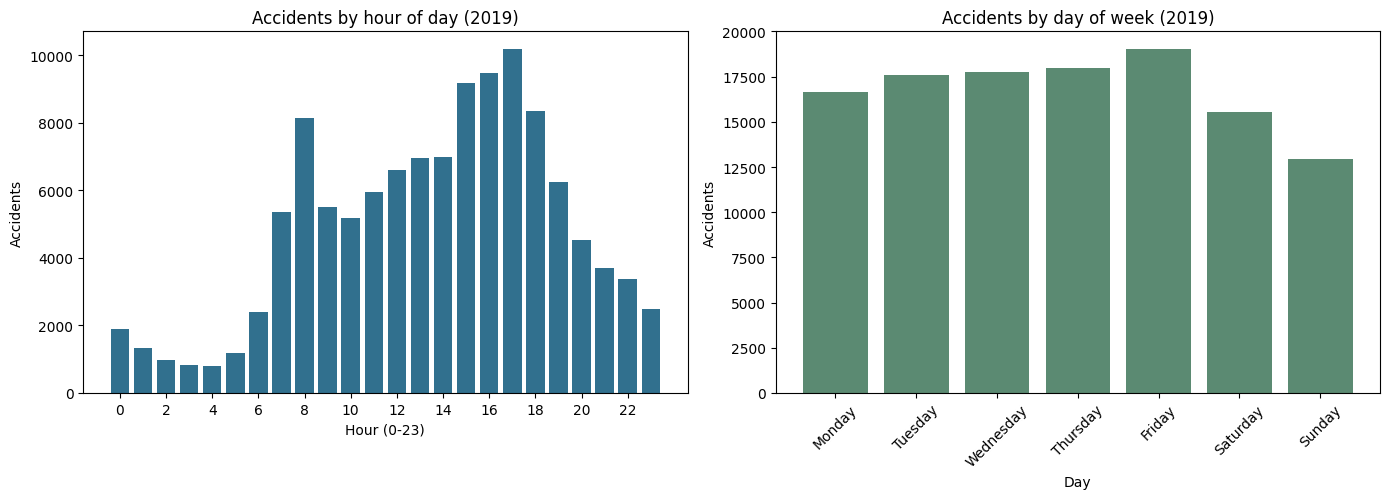

In [25]:
# Counts by hour and by day (ordered Mon to Sun for readability).
hour_counts = acc_2019["hour"].value_counts().sort_index()

day_counts = (acc_2019["day_name"].value_counts()
              .reindex(DAY_ORDER))

# Uniform null for hours; true weekday frequencies as the null for days
# (2019 has 53 Tuesdays) so the day test isn't skewed by the calendar.
weekday_freq = (acc_2019["date_parsed"].dropna().dt.normalize().drop_duplicates()
                .dt.day_name().value_counts().reindex(DAY_ORDER).values)
chi2_uniform(hour_counts, "Hour of day")
chi2_uniform(day_counts,  "Day of week", expected=weekday_freq)

# Visualising the accidents by day and by week
fig, axes = plt.subplots(1, 2, figsize=(14, 5.1))
axes[0].bar(hour_counts.index, hour_counts.values, color="#31708E")
axes[0].set(title="Accidents by hour of day (2019)",
            xlabel="Hour (0-23)", ylabel="Accidents")
axes[0].set_xticks(range(0, 24, 2))

axes[1].bar(day_counts.index, day_counts.values, color="#5B8A72")
axes[1].set(title="Accidents by day of week (2019)",
            xlabel="Day", ylabel="Accidents")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("accident_by_hour_by_day.png", dpi=150, bbox_inches="tight")
plt.show()


### Section 3.2: Q1 Part B: Motorcycle accidents by engine-capacity band

Motorcycles are mapped to three bands from `vehicle_type`
(2,3 → ≤125cc; 4 → 125-500cc; 5 → >500cc). We test whether accident timing
(hour, day) differs *significantly* by band, and interpret why commuter-class
and leisure-class machines might show different temporal signatures.

Join the vehicle table, map each motorcycle to a capacity band, and attempt to recover the records whose band is not directly coded.

In [26]:
# Pull every motorcycle vehicle_type, including the two that carry no usable band on their own
moto = run_query(f"""
    SELECT accident_index, vehicle_type, engine_capacity_cc
    FROM vehicle
    WHERE accident_year = 2019
      AND vehicle_type IN {MOTORCYCLE_TYPES};
""")

moto["band"] = moto["vehicle_type"].map(MOTORCYCLE_BANDS)

def cc_to_band(cc: int) -> Union[str, float]:
    """Map a valid engine capacity to a band; NaN if sentinel/out of range."""
    if cc is None or cc <= 0:
        return np.nan
    if cc <= 125:  return BAND_125
    if cc <= 500:  return BAND_MID
    return BAND_LARGE

# Attempt to recover type-97 ("unknown cc") records from engine_capacity_cc rather than discarding them
unknown  = moto["band"].isna() & (moto["vehicle_type"] == MOTORCYCLE_UNKNOWN_TYPE)
valid_cc = moto["engine_capacity_cc"].between(1, 3000)   # excludes -1 and 99999
moto.loc[unknown & valid_cc, "band"] = (
    moto.loc[unknown & valid_cc, "engine_capacity_cc"].apply(cc_to_band)
)

n_electric  = int((moto["vehicle_type"] == MOTORCYCLE_ELECTRIC_TYPE).sum())
n_unknown   = int(unknown.sum())
n_recovered = int((unknown & valid_cc).sum())
n_dropped   = int(moto["band"].isna().sum())

print(f"Motorcycle records (2019): {len(moto):,}")
print(f"  type 97 (unknown cc):        {n_unknown:,}")
print(f"    recovered via engine_cc:   {n_recovered:,}")
print(f"  type 23 (electric):          {n_electric:,}  [no cc equivalent: excluded]")
print(f"  unresolved, dropped:         {n_dropped:,} "
      f"({n_dropped / len(moto):.1%} of motorcycle records)")
print()
print(moto["band"].value_counts().reindex(BAND_ORDER).to_string())

# Why the recovery rate is what it is: checking the cc values actually carried
# by the unresolved records, split by type so the two causes are not conflated.
for vt, label in [(MOTORCYCLE_UNKNOWN_TYPE, "type 97 (unknown cc)"),
                  (MOTORCYCLE_ELECTRIC_TYPE, "type 23 (electric)")]:
    sub = moto.loc[moto["band"].isna() & (moto["vehicle_type"] == vt),
                   "engine_capacity_cc"]
    print(f"\nengine_capacity_cc on unresolved {label}, n={len(sub):,}:")
    print(sub.value_counts().head(5).to_string())

# Any type-97 record carrying a usable cc would have been recovered above; if
# recovery is zero, it is because the field is sentinel-coded on every one of them.

Motorcycle records (2019): 17,369
  type 97 (unknown cc):        415
    recovered via engine_cc:   0
  type 23 (electric):          65  [no cc equivalent: excluded]
  unresolved, dropped:         480 (2.8% of motorcycle records)

band
<=125cc      9542
125-500cc    2119
>500cc       5228

engine_capacity_cc on unresolved type 97 (unknown cc), n=415:
engine_capacity_cc
-1    415

engine_capacity_cc on unresolved type 23 (electric), n=65:
engine_capacity_cc
-1      56
 125     4
 49      1
 101     1
 999     1


Attach the accident timing to each motorcycle record.

In [27]:
# Merging the accident index and the day_name
moto_time = moto.merge(
    acc_2019[["accident_index", "hour", "day_name"]],
    on="accident_index", how="inner"
).dropna(subset=["band"])

print(f"Motorcycle-accident records with timing: {len(moto_time):,}")
print(moto_time.groupby("band", observed=True).size().reindex(BAND_ORDER).to_string())

Motorcycle-accident records with timing: 16,889
band
<=125cc      9542
125-500cc    2119
>500cc       5228


Cross-tabulate hour and day against capacity band, and test whether timing is independent of band.

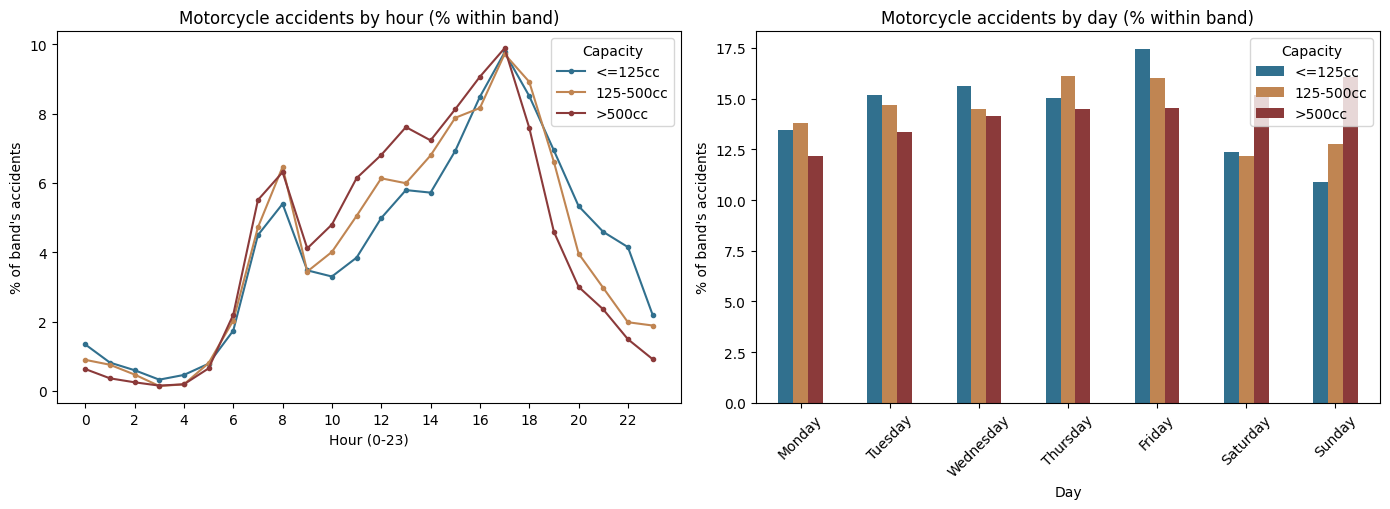

[Band x Day-of-week] chi2=132.8, dof=12, p=1.72e-22, V=0.06 -> variables are dependent
[Band x Hour-of-day] chi2=437.9, dof=46, p=2.47e-65, V=0.11 -> variables are dependent


In [28]:
# Normalised profiles for each band's % of accidents in each hour / day,
# so we compare the shape not raw volume, since the bands differ substantially in size.
hour_by_band = (moto_time.groupby(["band", "hour"], observed=True).size()
                .unstack(fill_value=0).reindex(BAND_ORDER))
hour_pct = hour_by_band.div(hour_by_band.sum(axis=1), axis=0) * 100

day_by_band = (moto_time.groupby(["band", "day_name"], observed=True).size()
               .unstack(fill_value=0).reindex(BAND_ORDER)[DAY_ORDER])
day_pct = day_by_band.div(day_by_band.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for band in BAND_ORDER:
    axes[0].plot(hour_pct.columns, hour_pct.loc[band], marker="o",
                 ms=3, color=BAND_COLORS[band], label=band)
axes[0].set(title="Motorcycle accidents by hour (% within band)",
            xlabel="Hour (0-23)", ylabel="% of band's accidents")
axes[0].set_xticks(range(0, 24, 2)); axes[0].legend(title="Capacity")

day_pct.T.plot(kind="bar", ax=axes[1],
               color=[BAND_COLORS[b] for b in BAND_ORDER])
axes[1].set(title="Motorcycle accidents by day (% within band)",
            xlabel="Day", ylabel="% of band's accidents")
axes[1].tick_params(axis="x", rotation=45); axes[1].legend(title="Capacity")
plt.tight_layout(); 
plt.savefig("motorcycle_accidents_by_hour_day.png", dpi=150, bbox_inches="tight")
plt.show()

# Significance: is timing dependent on band?
chi2_independence(day_by_band, "Band x Day-of-week")
chi2_independence(hour_by_band, "Band x Hour-of-day")

### Section 3.3: Q1 Part C: Pedestrian casualties by hour and day

Pedestrian casualties (`casualty_class = 3`) in 2019. We test whether their
temporal distribution is significantly non-uniform, and compare it against the
overall accident pattern to see whether pedestrians peak at *different* times
(e.g. school runs, evening darkness) than traffic accidents generally.

Extract pedestrian casualties, attach their timing, and test the distribution for significance.

Pedestrian casualties (2019) with timing: 21,770
[Pedestrian - hour] chi2=10,514.3, df=23, p=0, w=0.69 -> significant (vs uniform)
[Pedestrian - day] chi2=621.9, df=6, p=4.42e-131, w=0.17 -> significant (vs uniform)


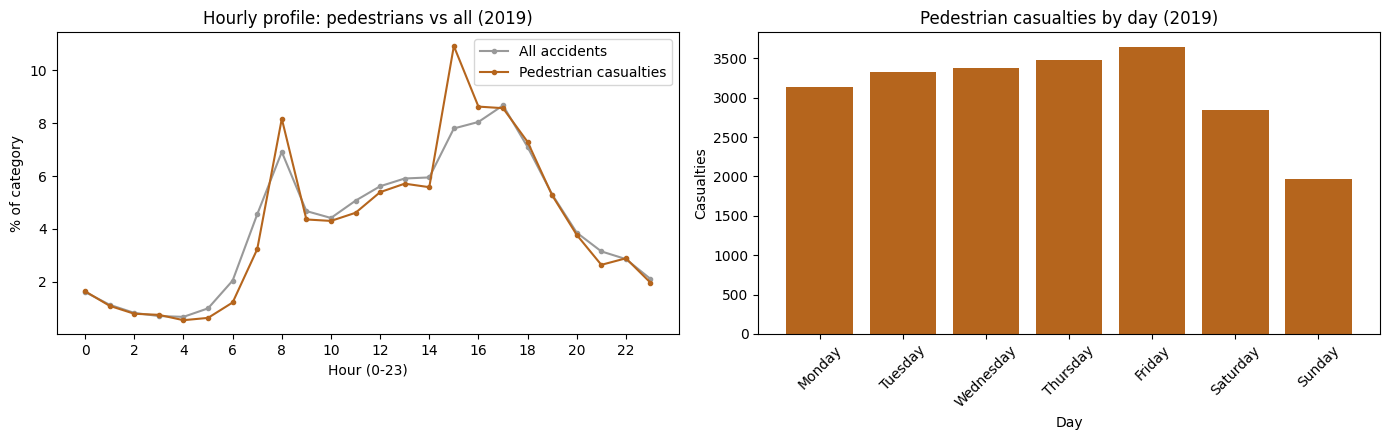

In [29]:
# Pedestrian casualties in 2019, joined to their accident timing.
ped = run_query("""
    SELECT accident_index, casualty_class
    FROM casualty
    WHERE accident_year = 2019 AND casualty_class = 3;
""")
ped_time = ped.merge(
    acc_2019[["accident_index", "hour", "day_name"]],
    on="accident_index", how="inner"
)
print(f"Pedestrian casualties (2019) with timing: {len(ped_time):,}")

ped_hour = ped_time["hour"].value_counts().sort_index()
ped_day  = ped_time["day_name"].value_counts().reindex(DAY_ORDER)

chi2_uniform(ped_hour, "Pedestrian - hour")
chi2_uniform(ped_day,  "Pedestrian - day")

# Compare pedestrian hour-profile vs all-accident hour-profile which is normalised.
all_hour_pct = (acc_2019["hour"].value_counts().sort_index()
                / len(acc_2019) * 100)
ped_hour_pct = ped_hour / ped_hour.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(all_hour_pct.index, all_hour_pct.values, marker="o", ms=3,
             color="#999999", label="All accidents")
axes[0].plot(ped_hour_pct.index, ped_hour_pct.values, marker="o", ms=3,
             color="#B5651D", label="Pedestrian casualties")
axes[0].set(title="Hourly profile: pedestrians vs all (2019)",
            xlabel="Hour (0-23)", ylabel="% of category")
axes[0].set_xticks(range(0, 24, 2)); axes[0].legend()

axes[1].bar(ped_day.index, ped_day.values, color="#B5651D")
axes[1].set(title="Pedestrian casualties by day (2019)",
            xlabel="Day", ylabel="Casualties")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); 
plt.savefig("pedestrians.png", dpi=150, bbox_inches="tight")
plt.show()

### Section 3.4: Q1 Part C (continued): Testing the school-run interpretation

The 15:00 pedestrian peak is only an *inference* from timing. The `casualty`
table records casualty age, so the interpretation is directly testable: if the
peak is a school-run effect, the under-16 share of pedestrian casualties should
be elevated in that hour specifically. This also tests the morning: a school-run
signal may be present at 08:00 but masked by the much larger commuter peak.


Pedestrian casualties with known age: 21,373 of 21,770 (98.2%)

Under-16 share of weekday pedestrian casualties
  15:00-15:59 : 53.8%  (n=2,046)
  08:00-08:59 : 49.2%  (n=1,685)
  all other h : 18.8%  (n=12,932)
  all hours   : 26.1%  (n=16,663)
[Hour==15 x casualty under 16] chi2=922.7, dof=1, p=1.11e-202, V=0.24 -> variables are dependent


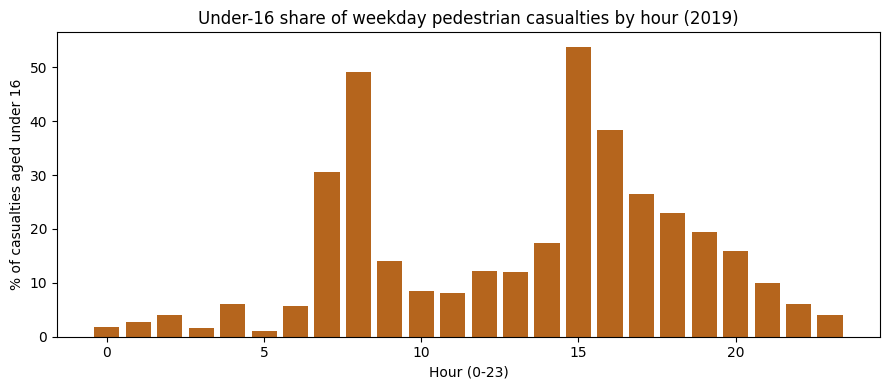

In [30]:
# Pedestrian casualties with age, joined to accident timing.
ped_age = run_query("""
    SELECT accident_index, age_of_casualty
    FROM casualty
    WHERE accident_year = 2019 AND casualty_class = 3;
""")
ped_age = ped_age.merge(acc_2019[["accident_index", "hour", "day_name"]],
                        on="accident_index", how="inner")

# -1 = age not known; excluded from the share rather than counted as adult.
known = ped_age[ped_age["age_of_casualty"] != MISSING].copy()
print(f"Pedestrian casualties with known age: {len(known):,} of {len(ped_age):,} "
      f"({len(known)/len(ped_age):.1%})")

known["under16"] = known["age_of_casualty"] < 16

# Weekdays only: the school run is a weekday phenomenon by definition.
weekday = known[~known["day_name"].isin(["Saturday", "Sunday"])]

share = weekday.groupby("hour")["under16"].agg(["mean", "size"])
share.columns = ["under16_share", "n"]

def share_at(hours):
    sub = weekday[weekday["hour"].isin(hours)]
    return sub["under16"].mean(), len(sub)

pm_share,  pm_n  = share_at([15])
am_share,  am_n  = share_at([8])
oth_share, oth_n = share_at([h for h in range(24) if h not in (8, 15)])
all_share = weekday["under16"].mean()

print(f"\nUnder-16 share of weekday pedestrian casualties")
print(f"  15:00-15:59 : {pm_share:.1%}  (n={pm_n:,})")
print(f"  08:00-08:59 : {am_share:.1%}  (n={am_n:,})")
print(f"  all other h : {oth_share:.1%}  (n={oth_n:,})")
print(f"  all hours   : {all_share:.1%}  (n={len(weekday):,})")

# Is the 15:00 under-16 share significantly different from other hours?
tbl = pd.crosstab(weekday["hour"].isin([15]), weekday["under16"])
chi2_independence(tbl, "Hour==15 x casualty under 16")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(share.index, share["under16_share"] * 100, color="#B5651D")

ax.set(title="Under-16 share of weekday pedestrian casualties by hour (2019)",
       xlabel="Hour (0-23)", ylabel="% of casualties aged under 16")
plt.tight_layout()
plt.savefig("pedestrian_under16_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()


## Section 4: Q2: Association Rule Mining on Accident Severity (Apriori)

We mine conditions associated with **severe** outcomes. Severity is binarised
(Fatal+Serious = *Severe*; Slight = *Slight*) to counter heavy class imbalance,
so severe-outcome rules can clear the support threshold. Categorical STATS19
codes are decoded to readable labels; rules are ranked by **lift** (association
above chance) with `Severe` as the consequent.

### Section 4.1: Mining the rules

Decode the 2019 accidents into a categorical transaction table for Apriori.

In [31]:
# STATS19 code dictionaries for the mined features (STATS20 guide; DfT, 2011). Every field maps its 
# own "unknown" code to an explicit token rather than leaving it to fall out as NaN
LIGHT   = {1: "daylight", 4: "dark-lit", 5: "dark-unlit",
           6: "dark-no-lighting", 7: "dark-unknown"}
WEATHER = {1: "fine", 2: "rain", 3: "snow", 4: "fine-winds",
           5: "rain-winds", 6: "snow-winds", 7: "fog", 8: "other", 9: "unknown"}
SURFACE = {1: "dry", 2: "wet", 3: "snow", 4: "ice",
           5: "flood", 6: "oil", 7: "mud", 9: "unknown"}
AREA    = {1: "urban", 2: "rural", 3: "unallocated"}
ROADTYP = {1: "roundabout", 2: "oneway", 3: "dual-cway",
           6: "single-cway", 7: "slip-road", 9: "unknown", 12: "oneway-slip"}

# Tokens that record "we do not know", as opposed to a real condition.
UNKNOWN_TOKENS = {"unknown", "unallocated", "dark-unknown"}

def build_transactions(df: pd.DataFrame, drop_unknown: bool = True) -> pd.DataFrame:
    """Decode 2019 accidents into a categorical transaction table for Apriori.

    Runs on the imputed columns from Section 2.1, so `speed_limit` and
    `road_surface_conditions` sentinels have already been recovered rather than
    excluded here.

    drop_unknown=True  -> exclude any row carrying a missing sentinel or a
                          recorded 'unknown' code in ANY mined field. Applied
                          uniformly across fields (the reported analysis).
    drop_unknown=False -> retain 'unknown' as an explicit category, so the
                          sample is preserved. Used as a sensitivity check that
                          the leading rules do not depend on this choice.
    """
    t = pd.DataFrame(index=df.index)
    t["sev"]     = np.where(df["accident_severity"].isin([1, 2]), "Severe", "Slight")
    t["speed"]   = "speed" + df["speed_limit"].astype(str)
    t["light"]   = df["light_conditions"].map(LIGHT)
    t["weather"] = df["weather_conditions"].map(WEATHER)
    t["surface"] = df["road_surface_conditions"].map(SURFACE)
    t["area"]    = df["urban_or_rural_area"].map(AREA)
    t["road"]    = df["road_type"].map(ROADTYP)

    before = len(t)
    t = t.dropna()                            # unmapped codes (incl. -1), NaN
    # Exact equality, not a substring search: the sentinel only ever appears as the whole value,
    # so testing == f"speed{MISSING}" is safer than scanning for "-1" anywhere in the token.
    t = t[t["speed"] != f"speed{MISSING}"]
    n_sentinel = before - len(t)

    n_unknown = 0
    if drop_unknown:
        mask = t.drop(columns="sev").isin(UNKNOWN_TOKENS).any(axis=1)
        n_unknown = int(mask.sum())
        t = t[~mask]

    print(f"Transactions: {len(t):,} of {before:,}  "
          f"({n_sentinel:,} missing/sentinel, {n_unknown:,} recorded-unknown; "
          f"{(before - len(t)) / before:.1%} excluded in total)")
    return t

trans = build_transactions(acc_2019)
base_rate = (trans["sev"] == "Severe").mean()
print(f"Base rate of Severe outcomes (GB-wide, 2019): {base_rate:.1%}")
trans.head()


Transactions: 110,222 of 117,536  (1 missing/sentinel, 7,313 recorded-unknown; 6.2% excluded in total)
Base rate of Severe outcomes (GB-wide, 2019): 21.5%


,sev,speed,light,weather,surface,area,road
252617,Slight,speed30,daylight,fine,dry,urban,roundabout
252618,Slight,speed30,dark-lit,fine,dry,urban,oneway
252619,Slight,speed30,dark-lit,fine,dry,urban,single-cway
252620,Severe,speed20,dark-lit,fine,dry,urban,single-cway
252621,Slight,speed30,dark-lit,fine,dry,urban,single-cway


One-hot encode the transactions and run Apriori.

In [32]:
# One-hot encode ("field=value" columns) for mlxtend (boolean matrix).
onehot = pd.get_dummies(trans)
print(f"One-hot matrix: {onehot.shape[0]:,} rows x {onehot.shape[1]} items")

# min_support = 0.02 (~2% of accidents): low enough to reach severe-condition
# combinations given the ~21% Severe base rate, high enough to stay meaningful.
MIN_SUPPORT = 0.02
freq = apriori(onehot, min_support=MIN_SUPPORT, use_colnames=True)
if freq.empty:
    raise ValueError(f"No itemsets at min_support={MIN_SUPPORT}; lower the threshold.")

# min_threshold=0 on lift keeps BOTH tails.
rules = association_rules(freq, metric="lift", min_threshold=0.0)
print(f"Frequent itemsets: {len(freq):,}   Rules (all lift): {len(rules):,}")


One-hot matrix: 110,222 rows x 32 items
Frequent itemsets: 1,093   Rules (all lift): 19,030


One-hot encoding above feeds Apriori. FP-Growth is a candidate alternative: it
builds a compact FP-tree instead of generating candidate itemsets level by
level, so it is typically faster on large, dense transaction sets. It is *not*
a different result, though: at a fixed minimum support the two algorithms
enumerate the **same** frequent itemsets, differing only in how they get there.
Apriori is retained for the reported analysis because the transaction set is
small enough that its speed disadvantage is irrelevant and its level-wise
output is easier to reason about; the cell below verifies the two agree so that
choice is a justified preference rather than an untested assumption.

In [33]:
# Alternative frequent-itemset miner. itemsets at the same min_support; 
freq_fp = fpgrowth(onehot, min_support=MIN_SUPPORT, use_colnames=True)

sets_apriori = {frozenset(s) for s in freq["itemsets"]}
sets_fpgrowth = {frozenset(s) for s in freq_fp["itemsets"]}
identical = sets_apriori == sets_fpgrowth

print(f"Apriori itemsets   : {len(sets_apriori):,}")
print(f"FP-Growth itemsets : {len(sets_fpgrowth):,}")
print(f"Itemset sets identical: {identical}")
if not identical:
    only_a = len(sets_apriori - sets_fpgrowth)
    only_f = len(sets_fpgrowth - sets_apriori)
    print(f"  only in Apriori: {only_a}, only in FP-Growth: {only_f}")
assert identical, "FP-Growth and Apriori disagree at the same min_support"
print("identical itemsets; Apriori retained for interpretability, not for a different result.")

Apriori itemsets   : 1,093
FP-Growth itemsets : 1,093
Itemset sets identical: True
identical itemsets; Apriori retained for interpretability, not for a different result.


Keep the rules pointing to Severe outcomes, rank them by lift, and visualise both tails.

Rules -> Severe: 151

HIGHEST lift (severity-prone conditions):
                                                               conditions  support  confidence     lift
                 area_rural, road_single-cway, speed_speed60, surface_dry 0.024351    0.358776 1.669409
   area_rural, road_single-cway, speed_speed60, surface_dry, weather_fine 0.023743    0.358003 1.665813
             light_daylight, road_single-cway, speed_speed60, surface_dry 0.020141    0.356913 1.660743
                             road_single-cway, speed_speed60, surface_dry 0.024850    0.356409 1.658395
               road_single-cway, speed_speed60, surface_dry, weather_fine 0.024215    0.355487 1.654109
area_rural, light_daylight, road_single-cway, speed_speed60, weather_fine 0.023099    0.344986 1.605247
                area_rural, road_single-cway, speed_speed60, weather_fine 0.030039    0.343929 1.600325
            light_daylight, road_single-cway, speed_speed60, weather_fine 0.023534    0.343122 1.596570


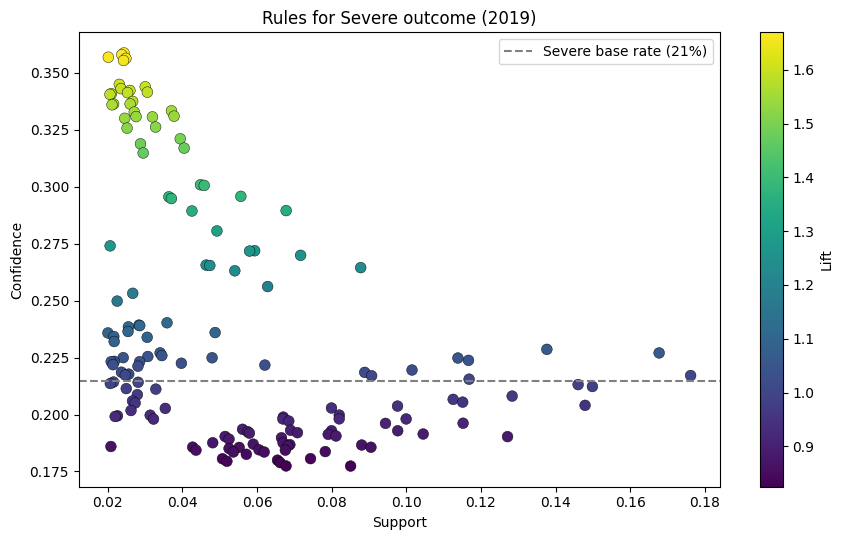

In [34]:
def has_sev(items) -> bool:
    """True if an itemset contains the severity target (must not be an antecedent)."""
    return any(str(x).startswith("sev_") for x in items)

severe = rules[rules["consequents"] == frozenset({"sev_Severe"})].copy()
severe = severe[~severe["antecedents"].apply(has_sev)]
severe["conditions"] = severe["antecedents"].apply(lambda s: ", ".join(sorted(s)))
severe = severe.sort_values(["lift", "confidence"], ascending=False)

print(f"Rules -> Severe: {len(severe):,}\n")
print("HIGHEST lift (severity-prone conditions):")
print(severe[["conditions", "support", "confidence", "lift"]]
      .head(8).to_string(index=False))

print("\nLOWEST lift (protective conditions: severity is under-represented):")
print(severe[["conditions", "support", "confidence", "lift"]]
      .tail(8).to_string(index=False))

# Scatterplot: support vs confidence which is coloured by lift, both tails visible.
fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(severe["support"], severe["confidence"],
                c=severe["lift"], s=60, cmap="viridis", edgecolor="k", lw=0.3)
ax.axhline(base_rate, ls="--", color="grey",
           label=f"Severe base rate ({base_rate:.0%})")
ax.set(title="Rules for Severe outcome (2019)",
       xlabel="Support", ylabel="Confidence")
ax.legend()
plt.colorbar(sc, label="Lift")
plt.tight_layout()
plt.savefig("rules_severe_outcome_2019.png", dpi=150, bbox_inches="tight")
plt.show()


### Section 4.2: Enrichment is not coverage

A rule's lift says how far its antecedent is *enriched* for severe outcomes. It
says nothing about how many severe accidents actually sit there. The share of
**all** severe accidents a rule accounts for is

$$P(\text{antecedent} \cap \text{Severe}) \;/\; P(\text{Severe})
= \frac{\text{support} \times \text{confidence}}{\text{base rate}}$$

and a recommendation needs both numbers. A condition set can be strongly
enriched and still be far too rare to move the national severe total, so a
ranking by lift alone can point policy at a real but marginal target.

The cell below walks one nested chain of antecedents, from the top-ranked rule
down to the bare speed limit. Each step differs from the last by a single
dropped condition, which isolates the trade-off instead of comparing unrelated
rules that happen to sit elsewhere in the ranking.

Severe base rate: 21.5%   (min_support = 0.02)

Enrichment vs coverage along one nested chain of antecedents:

                                                            conditions support confidence lift severe_share
area_rural, road_single-cway, speed_speed60, surface_dry, weather_fine   2.37%      35.8% 1.67         4.0%
              area_rural, road_single-cway, speed_speed60, surface_dry   2.44%      35.9% 1.67         4.1%
                           area_rural, road_single-cway, speed_speed60   3.71%      33.3% 1.55         5.8%
                                       road_single-cway, speed_speed60   3.78%      33.1% 1.54         5.8%
                                                         speed_speed60   4.05%      31.7% 1.47         6.0%

Highest-lift rule    : lift 1.67, reaches 4.1% of all severe accidents
  area_rural, road_single-cway, speed_speed60, surface_dry
Widest coverage at lift >= 1.2: lift 1.23, reaches 10.8% of all severe accidents
  area_rural


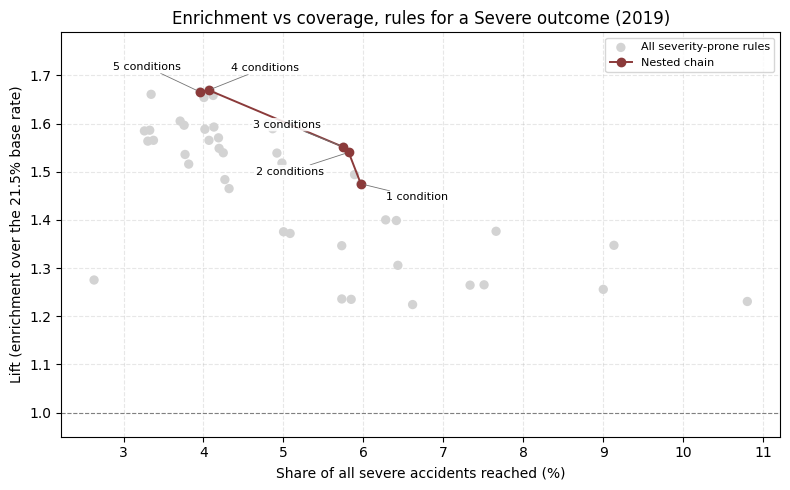

In [35]:
# severe_share = P(antecedent AND Severe) / P(Severe), that is the fraction of all
# severe accidents that this rule's antecedent reaches.
severe["severe_share"] = severe["support"] * severe["confidence"] / base_rate

NESTED = [
    {"area_rural", "road_single-cway", "speed_speed60", "surface_dry", "weather_fine"},
    {"area_rural", "road_single-cway", "speed_speed60", "surface_dry"},
    {"area_rural", "road_single-cway", "speed_speed60"},
    {"road_single-cway", "speed_speed60"},
    {"speed_speed60"},
]


def _pct(x, dp=1):
    """Percentage string that survives an itemset below min_support."""
    return "n/a" if pd.isna(x) else f"{x:.{dp}%}"


rows = []
for items in NESTED:
    match = severe[severe["antecedents"] == frozenset(items)]
    if match.empty:
        # Not in the mined ruleset: below MIN_SUPPORT or never generated.
        # Emit NaN so all five NESTED links stay in the table.
        rows.append({"conditions": ", ".join(sorted(items)), "support": np.nan,
                     "confidence": np.nan, "lift": np.nan, "severe_share": np.nan})
        continue
    r = match.iloc[0]
    rows.append({"conditions": r["conditions"], "support": r["support"],
                 "confidence": r["confidence"], "lift": r["lift"],
                 "severe_share": r["severe_share"]})

coverage = pd.DataFrame(rows)

print(f"Severe base rate: {base_rate:.1%}   (min_support = {MIN_SUPPORT})\n")
print("Enrichment vs coverage along one nested chain of antecedents:\n")
print(coverage.assign(
        support=lambda d: d["support"].map(lambda v: _pct(v, 2)),
        confidence=lambda d: d["confidence"].map(_pct),
        lift=lambda d: d["lift"].map(lambda v: "n/a" if pd.isna(v) else f"{v:.2f}"),
        severe_share=lambda d: d["severe_share"].map(_pct),
      ).to_string(index=False))


# Select the highest-lift and widest-coverage rules.
#
# lift > 1 alone admits rules at essentially chance enrichment (lift ~ 1.0), which
# can win on coverage without being informative: "fine weather" reaches a large
# share of severe accidents simply because most accidents happen in fine weather.
# MIN_LIFT sets the minimum enrichment margin for a rule to count as a target.

MIN_LIFT = 1.2
prone = severe[severe["lift"] >= MIN_LIFT]
top_lift = prone.iloc[0]
top_cov = prone.loc[prone["severe_share"].idxmax()]

print(f"\nHighest-lift rule    : lift {top_lift['lift']:.2f}, reaches "
      f"{top_lift['severe_share']:.1%} of all severe accidents")
print(f"  {top_lift['conditions']}")
print(f"Widest coverage at lift >= {MIN_LIFT}: lift {top_cov['lift']:.2f}, reaches "
      f"{top_cov['severe_share']:.1%} of all severe accidents")
print(f"  {top_cov['conditions']}")

# Enrichment and coverage trade off against each other along the chain.
# Offsets are staggered by condition count: the 5 and 4 condition rules sit
# almost on top of each other (they differ by one dropped condition), as do the
# 3 and 2 condition pair, so shallow offsets on both would overprint.

LABEL_OFFSETS = {5: (-14, 16, "right"), 4: (16, 14, "left"),
                 3: (-16, 14, "right"), 2: (-18, -16, "right"),
                 1: (18, -12, "left")}

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(prone["severe_share"] * 100, prone["lift"], s=45, c="lightgrey",
           edgecolor="none", label="All severity-prone rules", zorder=2)

_chain = coverage.dropna(subset=["lift"])
ax.plot(_chain["severe_share"] * 100, _chain["lift"], marker="o",
        color="#8B3A3A", lw=1.4, label="Nested chain", zorder=3)

for _, r in _chain.iterrows():
    n_cond = r["conditions"].count(",") + 1
    dx, dy, ha = LABEL_OFFSETS.get(n_cond, (8, 6, "left"))
    ax.annotate(f"{n_cond} condition{'s' if n_cond != 1 else ''}",
                (r["severe_share"] * 100, r["lift"]),
                textcoords="offset points", xytext=(dx, dy),
                ha=ha, fontsize=8, zorder=4,
                arrowprops=dict(arrowstyle="-", color="0.45", lw=0.6,
                                shrinkA=0, shrinkB=3),
                bbox=dict(boxstyle="round,pad=0.15", fc="white",
                          ec="none", alpha=0.85))

ax.axhline(1.0, ls="--", color="grey", lw=0.8)
# Headroom so the topmost label is not clipped by the axes frame.
ax.set_ylim(0.95, _chain["lift"].max() + 0.12)
ax.set(title="Enrichment vs coverage, rules for a Severe outcome (2019)",
       xlabel="Share of all severe accidents reached (%)",
       ylabel="Lift (enrichment over the 21.5% base rate)")
ax.grid(True, linestyle="--", alpha=0.3, zorder=1)
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig("rules_lift_vs_coverage.png", dpi=150, bbox_inches="tight")
plt.show()


### Section 4.3: Sensitivity check

Do the leading rules depend on how the 'unknown' codes are handled?

In [36]:
# Re-running the whole chain
trans_keep = build_transactions(acc_2019, drop_unknown=False)
freq_keep = apriori(pd.get_dummies(trans_keep), min_support=MIN_SUPPORT,
                    use_colnames=True)
rules_keep = association_rules(freq_keep, metric="lift", min_threshold=0.0)

sev_keep = rules_keep[rules_keep["consequents"] == frozenset({"sev_Severe"})].copy()
sev_keep = sev_keep[~sev_keep["antecedents"].apply(has_sev)]
sev_keep["conditions"] = sev_keep["antecedents"].apply(lambda s: ", ".join(sorted(s)))
sev_keep = sev_keep.sort_values("lift", ascending=False)

print("\nTop 3 rules, 'unknown' RETAINED as a category:")
print(sev_keep[["conditions", "support", "confidence", "lift"]]
      .head(3).to_string(index=False))
print(f"\nBase rate under this treatment: "
      f"{(trans_keep['sev'] == 'Severe').mean():.1%}")


Transactions: 117,535 of 117,536  (1 missing/sentinel, 0 recorded-unknown; 0.0% excluded in total)

Top 3 rules, 'unknown' RETAINED as a category:
                                                            conditions  support  confidence     lift
area_rural, road_single-cway, speed_speed60, surface_dry, weather_fine 0.022351    0.357172 1.703881
              area_rural, road_single-cway, speed_speed60, surface_dry 0.023270    0.356259 1.699525
            road_single-cway, speed_speed60, surface_dry, weather_fine 0.022810    0.354630 1.691752

Base rate under this treatment: 21.0%


### Section 4.4: From association to prediction

The report structure asks for a model that can *predict* "the severity of
injuries sustained given the conditions they happen under". Apriori does not do
that. It measures how far a condition set is *enriched* for severe outcomes
relative to chance; it is a description of association, not a classifier, and a
lift of 1.67 is not a claim that the outcome can be called in advance.

So the prediction question is asked separately and directly, on exactly the same
features, and the answer is allowed to be discouraging. Two models are fitted on
a 75/25 stratified split: **logistic regression** (interpretable, coefficients
comparable to the rules) and **histogram gradient boosting** (able to find
interactions the linear model cannot). Both are scored by **ROC-AUC** and
**PR-AUC** against the correct baselines: 0.5 for ROC, and the ~21.5% Severe
base rate for PR. Accuracy is deliberately not reported, since predicting
"Slight" for every accident would score ~78.5% and know nothing.

The point of this section is convergent validity. If the classifier's strongest
coefficients are the same conditions Apriori raised to the top of the lift
ranking, two independent methods agree and the Q2 finding is not an artefact of
the support threshold.


Train 82,666 x 30 features | Test 27,556
Severe rate: train 21.5%, test 21.5% (stratified)

Discrimination on the held-out 25% (higher is better):
model                         ROC-AUC   PR-AUC
Logistic regression             0.588    0.275
Gradient boosting               0.588    0.277
Baseline (no skill)             0.500    0.215   <- ROC 0.5; PR = the Severe base rate

Logistic regression: strongest coefficients (log-odds of Severe)
  raises severity:
weather_fine-winds    0.304
speed_speed60         0.293
road_single-cway      0.289
surface_wet           0.109
weather_rain-winds    0.095
  lowers severity:
light_daylight    -0.222
weather_snow      -0.225
weather_other     -0.244
road_roundabout   -0.253
speed_speed20     -0.292


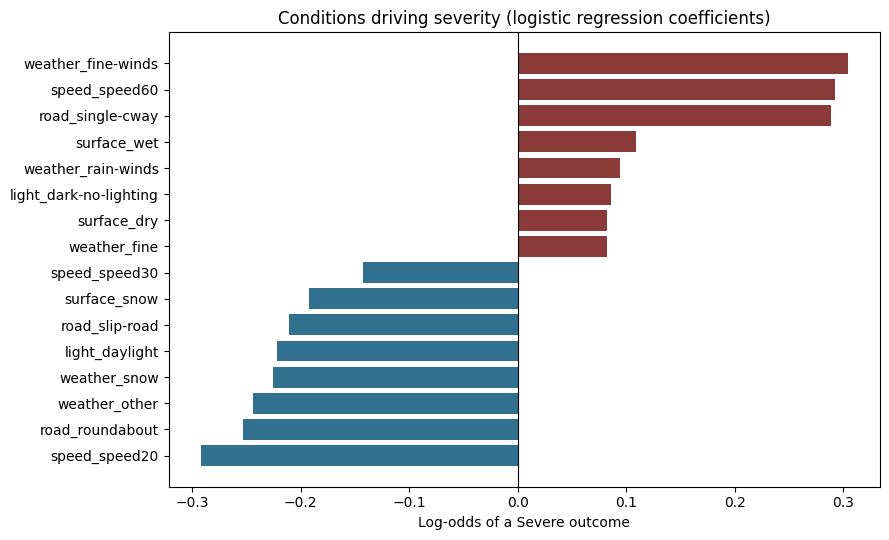

In [37]:
# Predict Severe vs Slight from the mined conditions alone.

# Same features as the rules, minus the target itself: the one-hot severity

y = (trans["sev"] == "Severe").astype(int).to_numpy()
X_cls = onehot.drop(columns=[c for c in onehot.columns if c.startswith("sev_")])

X_tr, X_te, y_tr, y_te = train_test_split(
    X_cls, y, test_size=0.25, random_state=SEED, stratify=y)
print(f"Train {X_tr.shape[0]:,} x {X_tr.shape[1]} features | Test {X_te.shape[0]:,}")
print(f"Severe rate: train {y_tr.mean():.1%}, test {y_te.mean():.1%} (stratified)")

# class_weight balances the 21/79 split so the model is not simply rewarded for
# predicting the majority class on every row.
logit = LogisticRegression(max_iter=2000, class_weight="balanced",
                           random_state=SEED).fit(X_tr, y_tr)
gbt = HistGradientBoostingClassifier(random_state=SEED,
                                     max_iter=200).fit(X_tr, y_tr)

print("\nDiscrimination on the held-out 25% (higher is better):")
print(f"{'model':<28}{'ROC-AUC':>9}{'PR-AUC':>9}")
for name, model in [("Logistic regression", logit),
                    ("Gradient boosting", gbt)]:
    p = model.predict_proba(X_te)[:, 1]
    print(f"{name:<28}{roc_auc_score(y_te, p):>9.3f}"
          f"{average_precision_score(y_te, p):>9.3f}")
print(f"{'Baseline (no skill)':<28}{0.5:>9.3f}{y_te.mean():>9.3f}"
      "   <- ROC 0.5; PR = the Severe base rate")

# Do the coefficients agree with the Apriori rules? Same data, different method:
# agreement is evidence the Q2 finding is real rather than threshold-dependent.
coefs = (pd.Series(logit.coef_[0], index=X_cls.columns)
         .sort_values(ascending=False))
print("\nLogistic regression: strongest coefficients (log-odds of Severe)")
print("  raises severity:")
print(coefs.head(5).round(3).to_string())
print("  lowers severity:")
print(coefs.tail(5).round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 5.5))
top = pd.concat([coefs.head(8), coefs.tail(8)]).sort_values()
ax.barh(top.index, top.values,
        color=["#31708E" if v < 0 else "#8B3A3A" for v in top.values])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Conditions driving severity (logistic regression coefficients)",
       xlabel="Log-odds of a Severe outcome")
plt.tight_layout()
plt.savefig("severity_classifier_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()


**Reading this result.** The AUCs are modest, and that is the finding, not a
failure to tune. Road type, speed limit, light, weather, surface and
urban/rural jointly shift the *odds* of a severe outcome substantially: the
strongest positive coefficients independently recover **60 mph** and
**single-carriageway**, the same conditions Apriori raised to the top of the
lift ranking, arrived at by a completely different route. `rural`'s own
marginal coefficient is weak, because its effect is absorbed by these
collinear partners (a rural road is where the 60 mph single carriageways are);
high-wind weather also raises severity, while the largest protective
coefficients are **20 mph** and **roundabout**. What the model does *not* do is
separate severe from slight accidents at the individual level. That is
mechanically sensible: severity is largely decided by impact energy and
occupant vulnerability, and STATS19's conditions fields are only a proxy for
those.

This matters for policy, and it is the honest version of the Q2 conclusion:
these variables identify *where risk is concentrated*, which is what an
infrastructure intervention needs, and they do not identify *which accident
will be serious*, which is what a targeting tool would need. Reporting only the
lift table would leave the reader unable to tell those two claims apart.


## Section 5: Q3: Spatial Clustering of Accidents in the Humberside Region

Accidents in the Humberside police-force area (Hull, East Riding, and North/
North-East Lincolnshire) for 2019, clustered on projected OSGR coordinates
(easting/northing, metres). We apply **K-Means** (regional structure, k chosen
by silhouette) and **DBSCAN** (density hotspots, eps chosen by a k-distance
plot) and compare what each reveals about the geographic distribution.

### Note on the regional filter scope

The brief permits identifying the region "by filtering on the LSOA, or police region or another method", so `police_force == 16` is one of the methods it names rather than a substitute for them. While a localized filter of Hull + East Riding yields 5,559 rows, `police_force == 16` yields 8,653 rows because it includes North and North East Lincolnshire. The full force boundary is used for regional analysis to capture estuary-wide transit corridors, which aligns with Humberside Police data tracking.

Build the regional 2019 spatial dataset (Humberside, valid coordinates).


In [38]:
# Region = Humberside force and year = 2019 which needs valid coordinates.
region = filter_region(acc_2019, mode="force").copy()
region = region.dropna(subset=["location_easting_osgr", "location_northing_osgr"])

X = region[["location_easting_osgr", "location_northing_osgr"]].to_numpy()
print(f"Regional accidents (2019, Humberside) with coordinates: {len(region):,}")
print(f"Easting range : {X[:,0].min():,.0f} to {X[:,0].max():,.0f} m")
print(f"Northing range: {X[:,1].min():,.0f} to {X[:,1].max():,.0f} m")

Regional accidents (2019, Humberside) with coordinates: 2,310
Easting range : 460,107 to 534,551 m
Northing range: 396,973 to 472,171 m


Fit K-Means, choosing k by silhouette score rather than by inspection.

Silhouette by k: {2: 0.469, 3: 0.578, 4: 0.631, 5: 0.659, 6: 0.652, 7: 0.497, 8: 0.5}
Chosen k = 5


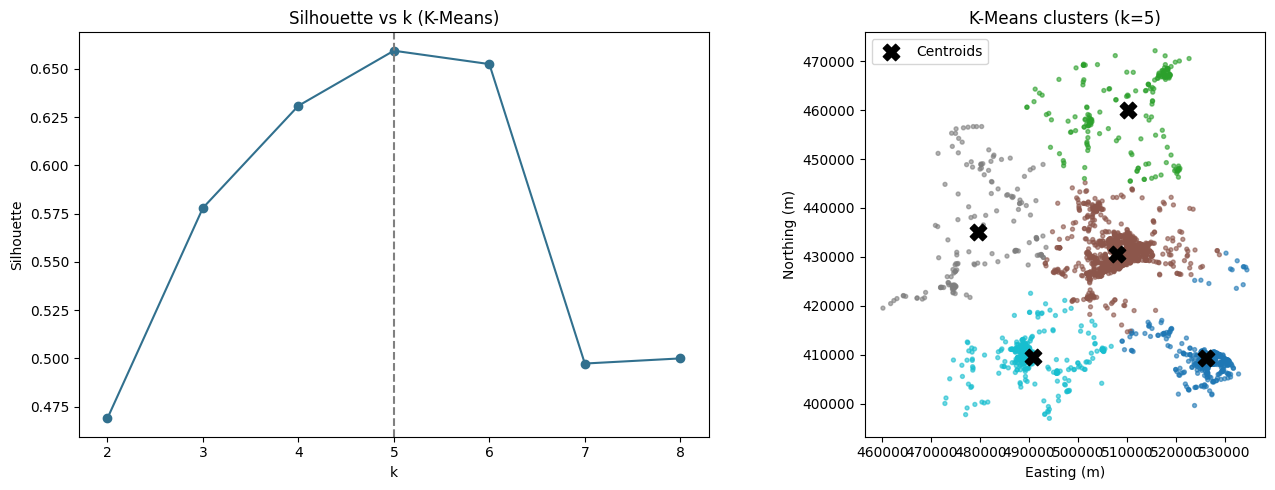

In [39]:
# Justify k: silhouette score across candidate k (higher = better separation).
sil = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X)
    sil[k] = silhouette_score(X, km.labels_, sample_size=2000, random_state=SEED)

best_k = max(sil, key=sil.get)
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()})
print(f"Chosen k = {best_k}")

km = KMeans(n_clusters=best_k, random_state=SEED, n_init=10).fit(X)
region["kmeans"] = km.labels_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(sil), list(sil.values()), marker="o", color="#31708E")
axes[0].axvline(best_k, ls="--", color="grey")
axes[0].set(title="Silhouette vs k (K-Means)", xlabel="k", ylabel="Silhouette")

sc = axes[1].scatter(X[:,0], X[:,1], c=km.labels_, cmap="tab10", s=8, alpha=0.6)
axes[1].scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1],
                c="black", marker="X", s=140, label="Centroids")
axes[1].set(title=f"K-Means clusters (k={best_k})",
            xlabel="Easting (m)", ylabel="Northing (m)")
axes[1].legend(); axes[1].set_aspect("equal")
plt.tight_layout(); 
plt.savefig("silhouette_vs_kmeans.png", dpi=150, bbox_inches="tight")
plt.show()

- DBSCAN with eps informed by the k-distance plot. At the knee (~129 m) the density criterion is so strict that 99% of points are classed as noise and only one hotspot survives (see sensitivity check below); relaxing eps to 500 m yields twelve interpretable, town-scale hotspots (65% noise) that an intervention could realistically target. The exact hotspot count is eps-sensitive, but the core structure, a few dense urban cores against a diffuse rural background, is robust.

k-distance knee ~ 129 m
DBSCAN (eps=500m, min_samples=15): 12 hotspots, 1,503 noise (65%)


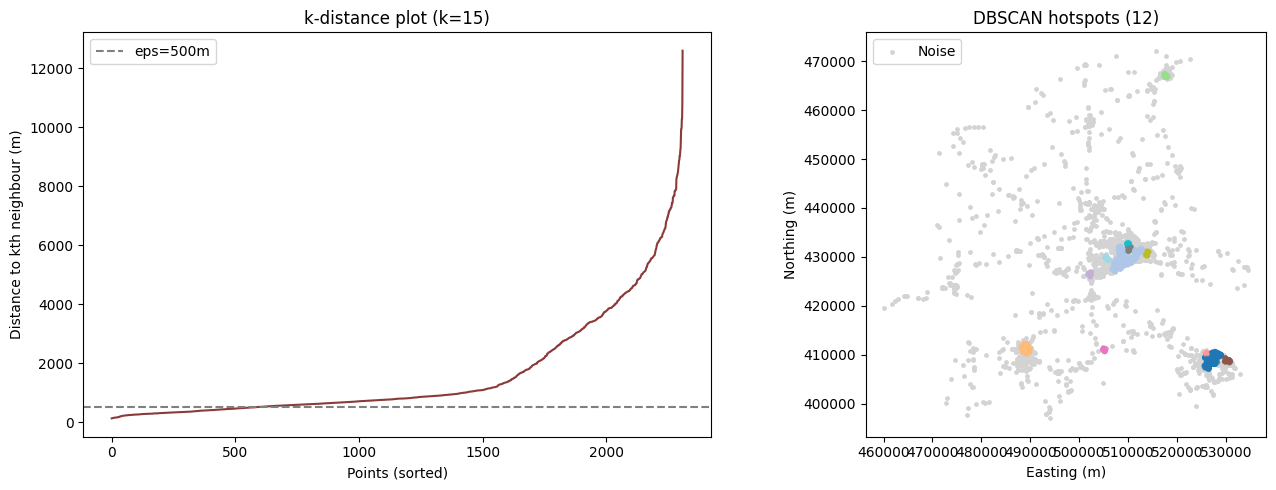

In [40]:
#  k-distance plot to sort each point's distance to its(min_samples-1)th neighbour; 
# min_samples=15 sets how many points constitute a hotspot.

MIN_SAMPLES = 15
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
kdist = np.sort(nn.kneighbors(X)[0][:, -1])

# Estimate the knee as the point of maximum distance from the chord joining

_line = np.linspace(kdist[0], kdist[-1], len(kdist))
knee_eps = float(kdist[np.argmax(kdist - _line)])
print(f"k-distance knee ~ {knee_eps:.0f} m")

# Knee (~129 m) = street-scale density; 500 m chosen for town-scale,
# policy-actionable hotspots 
EPS = 500

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X)
region["dbscan"] = db.labels_

n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_noise = int((db.labels_ == -1).sum())
print(f"DBSCAN (eps={EPS}m, min_samples={MIN_SAMPLES}): "
      f"{n_clusters} hotspots, {n_noise:,} noise ({n_noise/len(region):.0%})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(kdist, color="#8B3A3A")
axes[0].axhline(EPS, ls="--", color="grey", label=f"eps={EPS}m")
axes[0].set(title=f"k-distance plot (k={MIN_SAMPLES})",
            xlabel="Points (sorted)", ylabel="Distance to kth neighbour (m)")
axes[0].legend()

noise = db.labels_ == -1
axes[1].scatter(X[noise,0], X[noise,1], c="lightgrey", s=6, label="Noise")
axes[1].scatter(X[~noise,0], X[~noise,1], c=db.labels_[~noise],
                cmap="tab20", s=10, alpha=0.7)
axes[1].set(title=f"DBSCAN hotspots ({n_clusters})",
            xlabel="Easting (m)", ylabel="Northing (m)")
axes[1].legend(); axes[1].set_aspect("equal")
plt.tight_layout(); 
plt.savefig("k-distance_DBSCAN.png", dpi=150, bbox_inches="tight")
plt.show()

In [41]:
# Sensitivity: hotspot count at the knee-based eps vs the chosen 500 m.
for eps in (int(round(knee_eps)), 250, 500):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(X).labels_
    k = len(set(lab)) - (1 if -1 in lab else 0)
    print(f"eps={eps:>4} m: {k:>3} hotspots, noise={np.mean(lab == -1):.0%}")

eps= 129 m:   1 hotspots, noise=99%
eps= 250 m:   9 hotspots, noise=91%
eps= 500 m:  12 hotspots, noise=65%


### Section 5.1: What the hotspots actually are

Twelve unlabelled colours on a scatter plot are not a policy finding. A
recommendation to target a hotspot is only actionable if the hotspot can be
named, sized, and characterised so each DBSCAN cluster is resolved to its
district, its geographic centre, its accident count and its severity mix.

The severity column is the informative one. Section 4 found that severity
concentrates on rural high-speed roads while *frequency* concentrates in urban
centres. If that holds, the hotspots should show a severe share *below* the
regional average despite compressing a large share of the region's accidents
into a small fraction of its area, the two analyses would then be describing
the same mechanism from different directions, and this table is where they can
be checked against each other.


In [42]:
# Resolving each DBSCAN hotspot to a place and size as well as a severity profile.
hot = region[region["dbscan"] != MISSING].copy()

def _mode_district(s: pd.Series) -> str:
    """Modal ONS district of a cluster, mapped to its place name."""
    m = s.mode()
    return REGION_ONS.get(m.iloc[0], "Unknown") if len(m) else "Unknown"

hotspots = (hot.groupby("dbscan")
            .agg(accidents=("accident_index", "size"),
                 district=("local_authority_ons_district", _mode_district),
                 lat=("latitude", "mean"),
                 lon=("longitude", "mean"),
                 severe_pct=("accident_severity",
                             lambda s: 100 * s.isin([1, 2]).mean()))
            .sort_values("accidents", ascending=False))
hotspots.index.name = "cluster"

region_severe = 100 * region["accident_severity"].isin([1, 2]).mean()
clustered_share = len(hot) / len(region)


# DBSCAN can legitimately return no clusters at a strict eps

if hotspots.empty:
    print(f"DBSCAN (eps={EPS} m, min_samples={MIN_SAMPLES}) found NO clusters: "
          f"all {len(region):,} regional accidents are classed as noise at this "
          f"density. Raise eps or lower min_samples; the k-distance sensitivity "
          f"above shows the trade-off.")
else:
    print(f"DBSCAN hotspots (eps={EPS} m, min_samples={MIN_SAMPLES}): "
          f"{len(hotspots)} clusters holding {len(hot):,} of {len(region):,} "
          f"regional accidents ({clustered_share:.0%}); the remaining "
          f"{1 - clustered_share:.0%} is diffuse rural background.\n")
    print(hotspots.round({"lat": 3, "lon": 3, "severe_pct": 1}).to_string())

    hot_sev = 100 * hot["accident_severity"].isin([1, 2]).mean()
    noise_sev = 100 * region.loc[region["dbscan"] == MISSING,
                                 "accident_severity"].isin([1, 2]).mean()

    print(f"\nSevere rate, whole region        : {region_severe:.1f}%")
    print(f"Severe rate, inside hotspots     : {hot_sev:.1f}%")
    print(f"Severe rate, rural background    : {noise_sev:.1f}%")

# Based on Q2, frequency and severity should be different geographies. 
    print(f"\n Hotspots carry {clustered_share:.0%} of the region's accidents "
          f"at a {hot_sev:.1f}% severe rate; the diffuse background carries "
          f"{1 - clustered_share:.0%} at {noise_sev:.1f}%.")
    print("   " + ("CONSISTENT with Q2: frequency clusters in the urban cores, "
                   "severity does not."
                   if noise_sev > hot_sev else
                   "NOT consistent with Q2: severity is also concentrated in "
                   "the hotspots, and the Q2 reading should be revisited."))


DBSCAN hotspots (eps=500 m, min_samples=15): 12 clusters holding 807 of 2,310 regional accidents (35%); the remaining 65% is diffuse rural background.

         accidents                  district     lat    lon  severe_pct
cluster                                                                
1              378        Kingston upon Hull  53.751 -0.343        16.7
0              189   North East Lincolnshire  53.562 -0.081        15.3
2               69        North Lincolnshire  53.591 -0.655        10.1
6               32   North East Lincolnshire  53.560 -0.033         9.4
8               23        Kingston upon Hull  53.769 -0.330        17.4
7               19        North Lincolnshire  53.585 -0.414        15.8
9               18        Kingston upon Hull  53.760 -0.274        27.8
3               17  East Riding of Yorkshire  54.087 -0.202        17.6
4               17   North East Lincolnshire  53.573 -0.097        23.5
11              17        Kingston upon Hull  53.753 -0.

In [43]:
# Is the hotspot/background severity gap larger than chance?
zone = region["dbscan"].ne(MISSING).map({True: "hotspot", False: "background"})
outcome = (region["accident_severity"].isin([1, 2])
           .map({True: "severe", False: "slight"}))

sev_by_zone = pd.crosstab(zone, outcome)
print(sev_by_zone.to_string(), "\n")
print("Row percentages:")
print((100 * sev_by_zone.div(sev_by_zone.sum(axis=1), axis=0)).round(1).to_string(), "\n")

chi2_independence(sev_by_zone, "Hotspot vs background x severity")

hot_chi2, hot_p, _, _ = chi2_contingency(sev_by_zone.values)
hot_v = float(np.sqrt(hot_chi2 / (sev_by_zone.values.sum()
                                  * (min(sev_by_zone.shape) - 1))))
print(f"\nA significant but small effect (V = {hot_v:.2f}) is the honest reading: "
      "the gap is reliable, not large.")

accident_severity  severe  slight
dbscan                           
background            312    1191
hotspot               129     678 

Row percentages:
accident_severity  severe  slight
dbscan                           
background           20.8    79.2
hotspot              16.0    84.0 

[Hotspot vs background x severity] chi2=7.4, dof=1, p=0.00638, V=0.06 -> variables are dependent

A significant but small effect (V = 0.06) is the honest reading: the gap is reliable, not large.


### Section 5.2: Robustness of the regional boundary

The brief names "Kingston upon Hull, Humberside, and the East Riding of
Yorkshire". `police_force == 16` is the Humberside force area, so it also
carries North and North East Lincolnshire on the south bank. The full force is
used for the reported analysis for the reason given in the scope note above.

That is a defensible choice, but it is still a choice, so the narrower
Hull + East Riding filter is run here on identical settings. The question is
not whether the clusters change (they must, on a different point set) but
whether the frequency/severity split survives. If it does, the finding is a
property of the data rather than of where the boundary was drawn.

In [44]:
# Does the Q3 finding survive the narrower regional filter?

def cluster_profile(df: pd.DataFrame, label: str) -> dict:
    """K-Means (k by silhouette) and DBSCAN hotspot/severity split for one region."""
    d = df.dropna(subset=["location_easting_osgr", "location_northing_osgr"])
    Xr = d[["location_easting_osgr", "location_northing_osgr"]].to_numpy()
    if len(Xr) < MIN_SAMPLES:
        raise ValueError(f"{label}: only {len(Xr)} accidents carry coordinates; "
                         f"DBSCAN needs at least min_samples={MIN_SAMPLES}")

    sil_r = {k: silhouette_score(
                 Xr,
                 KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Xr).labels_,
                 sample_size=min(2000, len(Xr)), random_state=SEED)
             for k in range(2, 9)}
    best = max(sil_r, key=sil_r.get)

    lab = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Xr).labels_
    inside = lab != MISSING
    sev = d["accident_severity"].isin([1, 2]).to_numpy()

    def _rate(mask):
        # DBSCAN can return all-noise or all-clustered at a given eps
        return 100 * sev[mask].mean() if mask.any() else float("nan")

    return {"region": label, "n": len(d), "k": best,
            "silhouette": round(sil_r[best], 3),
            "hotspots": len(set(lab)) - (1 if MISSING in lab else 0),
            "clustered_%": round(100 * inside.mean(), 1),
            "severe_hot_%": round(_rate(inside), 1),
            "severe_bg_%": round(_rate(~inside), 1)}


profiles = pd.DataFrame([
    cluster_profile(filter_region(acc_2019, "force"),   "Humberside force (reported)"),
    cluster_profile(filter_region(acc_2019, "hull_er"), "Hull + East Riding only"),
])
print(profiles.to_string(index=False))

boundary_invariant = bool((profiles["severe_bg_%"] > profiles["severe_hot_%"]).all())
print(f"\nBackground severity exceeds hotspot severity under both definitions: "
      f"{boundary_invariant}")
print("The frequency/severity split is a property of the data, not of the "
      "regional boundary." if boundary_invariant else
      "The split does NOT survive the narrower filter; the Q3 reading must be "
      "restated as boundary-dependent.")

                     region    n  k  silhouette  hotspots  clustered_%  severe_hot_%  severe_bg_%
Humberside force (reported) 2310  5       0.659        12         34.9          16.0         20.8
    Hull + East Riding only 1475  3       0.673         7         32.6          17.3         21.3

Background severity exceeds hotspot severity under both definitions: True
The frequency/severity split is a property of the data, not of the regional boundary.


### Section 5.3: Combined figure

Assemble the K-Means and DBSCAN panels used in the written report.

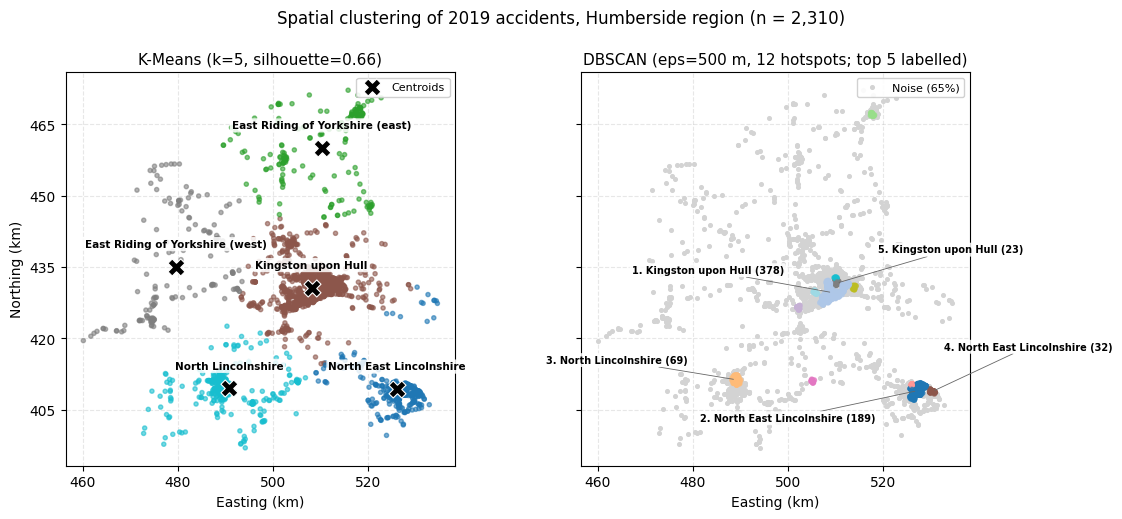

In [45]:
# K-Means regional structure vs DBSCAN density hotspots

centroid_labels = (region.groupby("kmeans")["local_authority_ons_district"]
                   .agg(_mode_district))


def _compass(centre, others):
    """Compass qualifier for one centroid against others sharing its name."""
    mx, my = np.mean([o[0] for o in others]), np.mean([o[1] for o in others])
    dx, dy = centre[0] - mx, centre[1] - my
    if abs(dy) >= abs(dx):
        return "north" if dy > 0 else "south"
    return "east" if dx > 0 else "west"


# A district can span more than one cluster
for name in centroid_labels[centroid_labels.duplicated(keep=False)].unique():
    ids = list(centroid_labels.index[centroid_labels == name])
    for i in ids:
        others = [km.cluster_centers_[j] for j in ids if j != i]
        centroid_labels[i] = f"{name} ({_compass(km.cluster_centers_[i], others)})"

noise = db.labels_ == MISSING
n_hot = len(set(db.labels_)) - (1 if MISSING in db.labels_ else 0)
noise_pct = noise.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)

# Left is K-Means
axes[0].scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="tab10", s=9, alpha=0.6, zorder=2)
axes[0].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
                c="black", marker="X", s=150, edgecolor="white", lw=0.8,
                label="Centroids", zorder=4)

for i, (cx, cy) in enumerate(km.cluster_centers_):
    # Sit the label clear of the centroid marker rather than on top of it.
    axes[0].annotate(centroid_labels.get(i, ""), (cx, cy),
                     textcoords="offset points", xytext=(0, 14),
                     ha="center", fontsize=7.5, fontweight="bold", zorder=5,
                     bbox=dict(boxstyle="round,pad=0.2", fc="white",
                               ec="none", alpha=0.85))

axes[0].set_title(f"K-Means (k={km.n_clusters}, silhouette={sil[best_k]:.2f})",
                  fontsize=11)
axes[0].set_ylabel("Northing (km)")
axes[0].legend(loc="upper right", fontsize=8, framealpha=0.9)
axes[0].set_aspect("equal")
axes[0].grid(True, linestyle="--", alpha=0.3, zorder=1)  # soft grid, behind the points

# Right is DBSCAN, with the five largest hotspots labelled by district
axes[1].scatter(X[noise, 0], X[noise, 1], c="lightgrey", s=7,
                label=f"Noise ({noise_pct:.0%})", zorder=2)
axes[1].scatter(X[~noise, 0], X[~noise, 1], c=db.labels_[~noise],
                cmap="tab20", s=11, alpha=0.75, zorder=3)

# Per-rank label offsets. Hotspots 2 and 4 sit side by side, so their leaders
# are pointed opposite ways: shallow offsets on both read as one line
label_offsets = {1: (-35, 14, "right"),   # Hull 378
                 2: (-30, -22, "right"),  # NE Lincs 189
                 3: (-35, 12, "right"),   # N Lincs 69
                 4: (8, 30, "left"),      # NE Lincs 32
                 5: (30, 22, "left")}     # Hull 23

for rank, (cid, row) in enumerate(hotspots.head(5).iterrows(), start=1):
    pts = region.loc[region["dbscan"] == cid,
                     ["location_easting_osgr", "location_northing_osgr"]]
    cx, cy = pts.iloc[:, 0].mean(), pts.iloc[:, 1].mean()
    dx, dy, ha = label_offsets.get(rank, (0, 9, "center"))
    

    label_text = f"{rank}. {row['district']} ({int(row['accidents'])})"
    
    axes[1].annotate(label_text, (cx, cy), 
                     textcoords="offset points", xytext=(dx, dy),
                     ha=ha, fontsize=7, fontweight="bold", zorder=5,
                     arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6,
                                     shrinkA=0, shrinkB=2),
                     bbox=dict(boxstyle="round,pad=0.2", fc="white",
                               ec="none", alpha=0.85))

axes[1].set_title(f"DBSCAN (eps={EPS} m, {n_hot} hotspots; top 5 labelled)",
                  fontsize=11)
axes[1].legend(loc="upper right", fontsize=8, framealpha=0.9)
axes[1].set_aspect("equal")
axes[1].grid(True, linestyle="--", alpha=0.3, zorder=1)  # soft grid, behind the points

# OSGR eastings/northings are six digits; at metre scale the tick labels
# collide on the shared axis. Relabel in kilometres and thin the ticks.
to_km = FuncFormatter(lambda v, _: f"{v/1000:.0f}")
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.yaxis.set_major_locator(MaxNLocator(6))
    ax.xaxis.set_major_formatter(to_km)
    ax.yaxis.set_major_formatter(to_km)
    ax.set_xlabel("Easting (km)")

fig.suptitle(f"Spatial clustering of 2019 accidents, Humberside region "
             f"(n = {len(region):,})", fontsize=12, y=0.99)
plt.tight_layout()
plt.savefig("q3_clustering_combined.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 6: Q4: Weekly Accident Forecasting by Police Force

For three forces of contrasting scale: Metropolitan (1, highest volume),
West Midlands (20, mid), Humberside (16, low): we build weekly accident-count
series, train on **2017-2018**, and forecast **2019**. Each force is modelled
with **SARIMA** (seasonal period 52) and benchmarked against a **seasonal-naive**
forecast (2019 week ≈ same week in 2018). With only two training years the
seasonal cycle is observed just twice, so the naive benchmark is essential:
if SARIMA fails to beat it, that under-sampling is the finding, not a defect.

Helpers: the cached weekly series, the SARIMA and seasonal-naive forecasts, the train/test split, and the accuracy metrics.

In [46]:
# The three forces, chosen for contrasting scale.
FORCES = {1: "Metropolitan", 20: "West Midlands", 16: "Humberside"}

# resample() labels a week by its END date; naming the anchor explicitly rather
# than relying on the "W" default makes the convention auditable.
WEEK_FREQ = "W-SUN"

# Each series is built once and reused. Section 6.1's AIC grid and 6.2's refit both need the same
# three series, and rebuilding them per call meant the same aggregation ran repeatedly for no gain.

_WEEKLY_CACHE: dict = {}

def weekly_series(force: int) -> pd.Series:
    """Continuous weekly accident counts for one police force (cached).

    Weeks with no accidents are filled with 0 rather than dropped, so the index
    is unbroken and the seasonal lag counts real weeks.
    """
    if force in _WEEKLY_CACHE:
        return _WEEKLY_CACHE[force]
    df = accidents[(accidents["police_force"] == force)
                   & (accidents["date_parsed"].notna())]
    s = df.set_index("date_parsed").resample(WEEK_FREQ).size()
    full = pd.date_range(s.index.min(), s.index.max(), freq=WEEK_FREQ)
    _WEEKLY_CACHE[force] = s.reindex(full, fill_value=0).asfreq(WEEK_FREQ)
    return _WEEKLY_CACHE[force]


def split_series(s: pd.Series):
    """Train on 2017-18, test on 2019, splitting on each week's SPAN not its label.

    A week is labelled by the Sunday it ends on, so the week ending 06 Jan 2019
    actually spans 31 Dec 2018 - 06 Jan 2019. Splitting on the label year alone 
    (s.index.year == 2019) would put a 2018 day inside the 2019 test set and push
    30-31 Dec 2019 into a 2020-labelled week. Weeks straddling a year boundary are 
    therefore excluded from both sets: neither is contaminated, at a cost of roughly
    one week per boundary, and the cost is printed.
    """
    week_start = s.index - pd.Timedelta(days=6)
    whole = week_start.year == s.index.year        # week lies inside one year
    train = s[whole & s.index.year.isin([2017, 2018])].asfreq(WEEK_FREQ)
    test  = s[whole & (s.index.year == 2019)].asfreq(WEEK_FREQ)
    return train, test


def forecast_sarima(train: pd.Series, test: pd.Series,
                    order=(1, 1, 1), seasonal_order=(1, 0, 0, 52)) -> np.ndarray:
    """Fit SARIMA on `train` and forecast onto the `test` index.

    The horizon is computed from the calendar gap between the end of training
    and the end of the test window, then the forecast is reindexed onto the test
    dates. Forecasting exactly `len(test)` steps would silently misalign by one
    week whenever a straddling week has been dropped between the two sets: the
    forecast would be scored against the wrong dates. Reindexing makes the
    alignment explicit and raises if the horizon fails to cover the test set.

    Relaxed stationarity/invertibility constraints aid convergence on the short
    (2-year) training history. If the optimiser fails, degrade gracefully to a
    mean-level forecast rather than aborting the whole run.
    """
    steps = int((test.index[-1] - train.index[-1]).days // 7)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                          enforce_stationarity=False,
                          enforce_invertibility=False).fit(disp=False)
        pred = res.forecast(steps).reindex(test.index)
        if pred.isna().any():
            raise ValueError("forecast horizon did not cover the test index")
        return pred.to_numpy()
    except Exception as exc:
        print(f"  SARIMA fit failed ({exc}); using mean-level fallback.")
        return np.full(len(test), float(train.mean()))


def forecast_naive(full: pd.Series, train: pd.Series,
                   test: pd.Series) -> np.ndarray:
    """Seasonal-naive: each 2019 week = the same week 52 weeks earlier (2018).

    The assertion is the point. A benchmark that reads an observation from
    inside the test window is not competing on the same information as the
    model, and would flatter itself. Here every source week must fall on or
    before the last training week, and that is checked rather than assumed.
    """
    src = test.index - pd.Timedelta(weeks=52)
    assert src.max() <= train.index[-1], (
        "seasonal-naive would read a test-period observation")
    pred = full.reindex(src)
    if pred.isna().any():
        raise ValueError("naive benchmark has gaps in its source weeks")
    return pred.to_numpy()


def metrics(actual, pred) -> dict:
    """MAE, RMSE and MAPE. MAPE skips zero-count periods to avoid /0."""
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    mae  = np.mean(np.abs(a - p))
    rmse = np.sqrt(np.mean((a - p) ** 2))
    nz = a != 0
    mape = np.mean(np.abs((a[nz] - p[nz]) / a[nz])) * 100 if nz.any() else np.nan
    # float() rather than the raw numpy scalars: on numpy >= 2 a np.float64 in a
    # dict reprs as "np.float64(0.8)"
    return {"MAE": round(float(mae), 2), "RMSE": round(float(rmse), 2),
            "MAPE%": round(float(mape), 1) if np.isfinite(mape) else float("nan")}


# Printing out the cost of the clean split.
_s = weekly_series(HUMBERSIDE_FORCE)
_tr, _te = split_series(_s)
print(f"Weekly series span : {_s.index.min().date()} to {_s.index.max().date()} "
      f"({len(_s)} weeks)")
print(f"Train (2017-18)    : {len(_tr)} whole weeks, "
      f"{_tr.index.min().date()} to {_tr.index.max().date()}")
print(f"Test  (2019)       : {len(_te)} whole weeks, "
      f"{_te.index.min().date()} to {_te.index.max().date()}")
print(f"Excluded as straddling a year boundary: "
      f"{int(((_s.index - pd.Timedelta(days=6)).year != _s.index.year).sum())} weeks")


Weekly series span : 2017-01-01 to 2021-01-03 (210 weeks)
Train (2017-18)    : 104 whole weeks, 2017-01-08 to 2018-12-30
Test  (2019)       : 51 whole weeks, 2019-01-13 to 2019-12-29
Excluded as straddling a year boundary: 4 weeks


Fit and score all three forces, and overlay the weekly forecasts against the 2019 actuals.

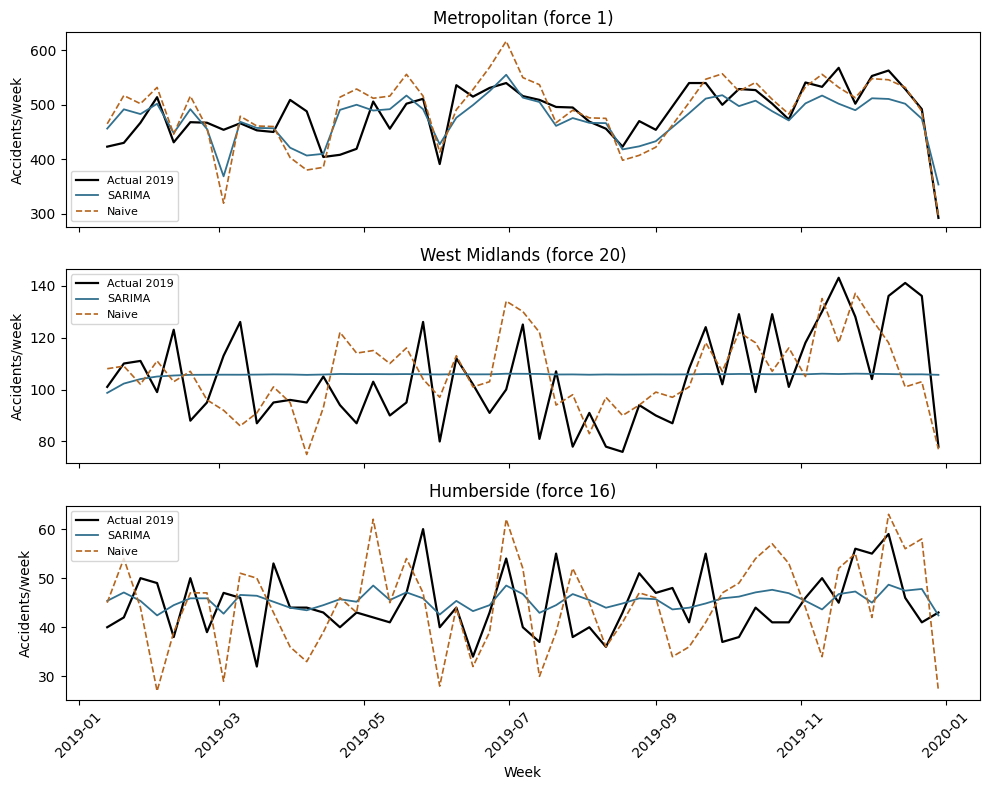

In [47]:
# Fit and score all three forces, then plot actual vs both forecasts.
results = []
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for ax, (force, name) in zip(axes, FORCES.items()):
    s = weekly_series(force)
    train, test = split_series(s)

    sarima_pred = forecast_sarima(train, test)
    naive_pred  = forecast_naive(s, train, test)

    m_s = metrics(test.values, sarima_pred)
    m_n = metrics(test.values, naive_pred)
    results.append({"Force": name, "Model": "SARIMA", **m_s})
    results.append({"Force": name, "Model": "Naive",  **m_n})

    ax.plot(test.index, test.values, color="black", lw=1.6, label="Actual 2019")
    ax.plot(test.index, sarima_pred, color="#31708E", lw=1.3, label="SARIMA")
    ax.plot(test.index, naive_pred,  color="#B5651D", ls="--", lw=1.2, label="Naive")
    ax.set(title=f"{name} (force {force})", ylabel="Accidents/week")
    ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)

# Shared x-axis: label it once, under the bottom panel only.
axes[-1].set_xlabel("Week")

plt.tight_layout()
plt.savefig("time_series_seasonal_vs_naive_yearly.png", dpi=150, bbox_inches="tight")
plt.show()


Assemble the accuracy table (MAE, RMSE, MAPE) per force and model.

In [48]:
# The DataFrame is indexed by force and model, to help to compare the error metrics like-for-like
res_df = (pd.DataFrame(results)
          .set_index(["Force", "Model"])
          .sort_index())
print(res_df.to_string())

                        MAE   RMSE  MAPE%
Force         Model                      
Humberside    Naive    8.75  10.48   19.9
              SARIMA   5.34   6.38   12.2
Metropolitan  Naive   33.55  46.99    7.1
              SARIMA  29.75  38.63    6.3
West Midlands Naive   14.80  18.26   14.4
              SARIMA  15.26  18.01   15.0


### Section 6.1: Justifying the SARIMA order

The reported models hold a fixed `(1,1,1)(1,0,0,52)` order across all three
forces so that the comparison between them is like-for-like rather than a
comparison of three differently-tuned models. That justifies holding the order
constant; it does not justify *that* order. Below it is selected on the
training data by AIC, per force, and the fixed-order result is checked against
it.

Seasonal differencing (`D=1`) is excluded from the grid: with 104 weekly
training observations and a 52-week period, differencing would leave 52 points
to identify the seasonal term, which is not enough to estimate it.


In [49]:
# AIC grid on training data only.
P_RANGE = Q_RANGE = range(0, 3)
D_RANGE = range(0, 2)
SEASONAL = [(0, 0, 0, 52), (1, 0, 0, 52), (0, 0, 1, 52)]
FIXED_ORDER, FIXED_SEASONAL = (1, 1, 1), (1, 0, 0, 52)


# slow grid is distinguishable from a stalled kernel.
N_CANDIDATES = len(P_RANGE) * len(D_RANGE) * len(Q_RANGE) * len(SEASONAL)


def select_order(train: pd.Series, label: str = "") -> pd.DataFrame:
    """Rank (order, seasonal_order) candidates by AIC on the training series."""
    rows, skipped = [], 0
    grid = itertools.product(P_RANGE, D_RANGE, Q_RANGE, SEASONAL)
    for n, (p, d, q, s_order) in enumerate(grid, start=1):
        print(f"\r  fitting {label} candidate {n}/{N_CANDIDATES} "
              f"{(p, d, q)}{s_order}      ", end="", flush=True)
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                res = SARIMAX(train, order=(p, d, q), seasonal_order=s_order,
                              enforce_stationarity=False,
                              enforce_invertibility=False).fit(disp=False)
            rows.append({"order": (p, d, q), "seasonal": s_order, "aic": res.aic})
        except Exception:
            skipped += 1
            continue                      # non-converging candidates are skipped
    print(f"\r  {label}: {len(rows)}/{N_CANDIDATES} candidates fitted"
          f"{f', {skipped} skipped' if skipped else ''}.".ljust(70))
    return pd.DataFrame(rows).sort_values("aic").reset_index(drop=True)

order_results = []
grid_start = time.perf_counter()
for force, name in FORCES.items():
    train, test = split_series(weekly_series(force))
    t_force = time.perf_counter()
    ranked = select_order(train, name)
    print(f"  {name} grid took {time.perf_counter() - t_force:.0f}s")
    best = ranked.iloc[0]
    fixed_row = ranked[(ranked["order"] == FIXED_ORDER) &
                       (ranked["seasonal"] == FIXED_SEASONAL)]
    fixed_aic  = float(fixed_row["aic"].iloc[0]) if len(fixed_row) else np.nan
    fixed_rank = int(fixed_row.index[0]) + 1 if len(fixed_row) else -1

    print(f"\n{name}")
    print(ranked.head(3).to_string(index=False))
    print(f"  fixed {FIXED_ORDER}{FIXED_SEASONAL}: AIC={fixed_aic:,.1f} "
          f"(rank {fixed_rank} of {len(ranked)}, "
          f"dAIC={fixed_aic - best['aic']:+.1f})")

    order_results.append({"Force": name, "force_id": force,
                          "order": best["order"], "seasonal": best["seasonal"],
                          "AIC-selected": f"{best['order']}{best['seasonal']}",
                          "Best AIC": round(best["aic"], 1),
                          "Fixed AIC": round(fixed_aic, 1),
                          "Fixed rank": fixed_rank,
                          "dAIC": round(fixed_aic - best["aic"], 1)})

print(f"\nFull AIC grid: {3 * N_CANDIDATES} fits in "
      f"{time.perf_counter() - grid_start:.0f}s")

print("\n\nOrder selection summary")
print(pd.DataFrame(order_results)[["Force", "AIC-selected", "Best AIC",
                                   "Fixed AIC", "dAIC", "Fixed rank"]]
      .to_string(index=False))

# Convention (Burnham and Anderson, 2004): dAIC < 2 = substantial support for the
# candidate, 4-7 = considerably less, > 10 = essentially none. The convention
# leaves 2-4 and 7-10 unnamed

for row in order_results:
    d = row["dAIC"]
    verdict = ("substantial support" if d < 2 else
               "considerably less support" if d <= 7 else
               "little support" if d <= 10 else
               "essentially no support")
    print(f"  {row['Force']:<14} dAIC={d:+6.1f} -> {verdict} for the fixed order")


  Metropolitan: 54/54 candidates fitted.                             
  Metropolitan grid took 22s

Metropolitan
    order      seasonal        aic
(2, 1, 1) (1, 0, 0, 52) 531.303153
(2, 1, 2) (1, 0, 0, 52) 533.198412
(0, 1, 2) (0, 0, 1, 52) 534.304559
  fixed (1, 1, 1)(1, 0, 0, 52): AIC=540.0 (rank 7 of 54, dAIC=+8.7)
  West Midlands: 54/54 candidates fitted.                            
  West Midlands grid took 19s

West Midlands
    order      seasonal        aic
(2, 1, 2) (0, 0, 1, 52) 390.077101
(0, 1, 2) (0, 0, 1, 52) 390.399892
(1, 1, 2) (0, 0, 1, 52) 391.506687
  fixed (1, 1, 1)(1, 0, 0, 52): AIC=401.5 (rank 12 of 54, dAIC=+11.5)
  Humberside: 54/54 candidates fitted.                               
  Humberside grid took 21s

Humberside
    order      seasonal        aic
(0, 1, 2) (0, 0, 1, 52) 361.621992
(1, 1, 2) (0, 0, 1, 52) 363.158533
(2, 1, 2) (0, 0, 1, 52) 366.060461
  fixed (1, 1, 1)(1, 0, 0, 52): AIC=374.8 (rank 11 of 54, dAIC=+13.1)

Full AIC grid: 162 fits in 61s


O

### Section 6.2: Does re-tuning change the conclusion?

Refit each force with its AIC-selected order and re-score it against the same 2019 test set. AIC ranks in-sample fit penalised for complexity; it carries no guarantee about forecast error, so whether the better-fitting order forecasts better is a real question rather than a rhetorical one.

Re-tuning fits each force with its AIC-selected order and re-scores on the same 2019 test set, answering two separate questions: (a) does the reported conclusion survive re-tuning, and (b) does minimising in-sample AIC actually improve out-of-sample accuracy? AIC ranks in-sample fit penalised for complexity and carries no guarantee about forecast error, so (b) is a genuine question, not a rhetorical one.

In [50]:
# Refit per force at its AIC-selected order, re-score on 2019: does the
# conclusion survive re-tuning, and does AIC help out-of-sample? 

MAPE_TOL = 0.05

def tuning_verdict(tuned_mape: float, fixed_mape: float) -> str:
    """Effect of re-tuning, at the precision MAPE is actually reported to."""
    delta = tuned_mape - fixed_mape
    if delta < -MAPE_TOL:
        return "better"
    if delta > MAPE_TOL:
        return "worse"
    return "no change"

tuned = []
for row in order_results:
    s = weekly_series(row["force_id"])
    wk_train, wk_test = split_series(s)

    pred = forecast_sarima(wk_train, wk_test,
                           order=row["order"], seasonal_order=row["seasonal"])
    m_tuned = metrics(wk_test.values, pred)
    m_naive = metrics(wk_test.values, forecast_naive(s, wk_train, wk_test))
    m_fixed = float(res_df.loc[(row["Force"], "SARIMA"), "MAPE%"])   # Section 6

    tuned.append({"Force": row["Force"],
                  "AIC order": row["AIC-selected"],
                  "Fixed MAPE%": m_fixed,
                  "Tuned MAPE%": m_tuned["MAPE%"],
                  "Naive MAPE%": m_naive["MAPE%"],
                  "Tuned beats naive": m_tuned["MAPE%"] < m_naive["MAPE%"],
                  "Effect of tuning": tuning_verdict(m_tuned["MAPE%"], m_fixed)})

tuned_df = pd.DataFrame(tuned)
print("Fixed order vs AIC-selected order vs seasonal-naive (2019 test set):")
print(tuned_df.to_string(index=False))

# Group forces by whether AIC tuning helped out-of-sample, and count how many
# selected orders differed from the fixed one.
by_effect = {v: tuned_df.loc[tuned_df["Effect of tuning"] == v, "Force"].tolist()
             for v in ("better", "worse", "no change")}
n_diff = int((tuned_df["AIC order"] != f"{FIXED_ORDER}{FIXED_SEASONAL}").sum())

print(f"\nAIC chose a different order from the fixed one for {n_diff} of "
      f"{len(tuned_df)} forces. Out-of-sample that order forecast:")
print(f"  better    : {', '.join(by_effect['better']) or 'none'}")
print(f"  worse     : {', '.join(by_effect['worse']) or 'none'}")
print(f"  no change : {', '.join(by_effect['no change']) or 'none'}"
      f"   (within {MAPE_TOL} pp, i.e. indistinguishable at reported precision)")
print("\nIn-sample fit and out-of-sample accuracy therefore select different")
print("models on these series: a better-fitting order is not reliably a")
print("better-forecasting one. A force that loses to seasonal-naive is not")
print("losing because the reported order was mis-chosen: re-tuning does not")
print("rescue it.")

# Residual diagnostic on the reported (fixed-order) model for one force:
# Ljung-Box tests whether residual autocorrelation remains at lags 1-10.
lb_train, _ = split_series(weekly_series(HUMBERSIDE_FORCE))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fit = SARIMAX(lb_train, order=FIXED_ORDER, seasonal_order=FIXED_SEASONAL,
                  enforce_stationarity=False,
                  enforce_invertibility=False).fit(disp=False)
lb = acorr_ljungbox(fit.resid, lags=[10], return_df=True)
lb_p = float(lb["lb_pvalue"].iloc[0])
print(f"\nLjung-Box on fixed-order Humberside residuals (lag 10): p={lb_p:.3f} "
      f"{'residuals not distinguishable from white noise' if lb_p > 0.05 else 'residual autocorrelation remains: structure the model has not captured'}")


Fixed order vs AIC-selected order vs seasonal-naive (2019 test set):
        Force              AIC order  Fixed MAPE%  Tuned MAPE%  Naive MAPE%  Tuned beats naive Effect of tuning
 Metropolitan (2, 1, 1)(1, 0, 0, 52)          6.3          6.4          7.1               True            worse
West Midlands (2, 1, 2)(0, 0, 1, 52)         15.0         15.1         14.4              False            worse
   Humberside (0, 1, 2)(0, 0, 1, 52)         12.2         11.5         19.9               True           better

AIC chose a different order from the fixed one for 3 of 3 forces. Out-of-sample that order forecast:
  better    : Humberside
  worse     : Metropolitan, West Midlands
  no change : none   (within 0.05 pp, i.e. indistinguishable at reported precision)

In-sample fit and out-of-sample accuracy therefore select different
models on these series: a better-fitting order is not reliably a
better-forecasting one. A force that loses to seasonal-naive is not
losing because the reported 

## Section 7: Q5: Daily Forecasting for Hull's Highest-Incident LSOAs

Ranking Hull (`E06000010`) LSOAs by accident count in **Jan-Mar 2019**, take the
**top 30**, and aggregate them into one daily series. We train on **Jan-Jun 2019**
and forecast **July 2019** daily counts, validating against actuals. Going daily
makes the relevant seasonality **weekly (period 7)**: the day-of-week cycle from
Q1, which, unlike Q4's annual cycle, is well-sampled (~26 cycles in training).
SARIMA(period 7) is benchmarked against a weekly-naive forecast.

Build the top-30 Hull-LSOA aggregate daily series, with an explicit and reproducible tie-break at the selection boundary.

`value_counts()` breaks ties by order of first appearance, an artefact of row order rather than a stated rule; with a cut-off this low several LSOAs tie on the boundary, so which ones make the top 30 would change if the table were sorted differently. Selection is ranked explicitly on (count descending, LSOA code ascending) so it is deterministic and the tie-break is declared rather than accidental.

In [51]:
# Hull accidents in 2019 with a valid LSOA and date. The LSOA sentinel was
# normalised to NaN at load (Section 0), so .notna() excludes it.
hull = accidents[(accidents["local_authority_ons_district"] == HULL_ONS)
                 & (accidents["accident_year"] == 2019)
                 & (accidents["lsoa_of_accident_location"].notna())
                 & (accidents["date_parsed"].notna())].copy()

# Audit what that filter cost, so the exclusion is visible rather than implicit.
hull_all = accidents[(accidents["local_authority_ons_district"] == HULL_ONS)
                     & (accidents["accident_year"] == 2019)]
n_no_lsoa = len(hull_all) - len(hull)
print(f"Hull accidents 2019: {len(hull_all):,} total, {len(hull):,} with a valid "
      f"LSOA ({n_no_lsoa:,} excluded for a missing/sentinel LSOA code).")

# Rank LSOAs by Jan-Mar 2019 count and take the top 30.
q1_2019 = hull[hull["month"].isin([1, 2, 3])]
q1_counts = q1_2019["lsoa_of_accident_location"].value_counts()

# Rank explicitly on (count DESC, LSOA ASC): deterministic and declared tie-break
# (value_counts() would break ties by row order)

q1_ranked = (q1_counts.rename("n").rename_axis("lsoa").reset_index()
             .sort_values(["n", "lsoa"], ascending=[False, True])
             .reset_index(drop=True))

TOP_N = 30
cutoff   = int(q1_ranked["n"].iloc[TOP_N - 1])
n_above  = int((q1_ranked["n"] > cutoff).sum())
n_tied   = int((q1_ranked["n"] == cutoff).sum())
top30 = q1_ranked["lsoa"].head(TOP_N).tolist()

print(f"\nLSOAs with >=1 accident in Q1 2019: {len(q1_ranked)}")
print(f"Top-{TOP_N} Q1 count range: {cutoff}-{int(q1_ranked['n'].iloc[0])} accidents")
print(f"Tie-break at the boundary: {n_above} LSOAs are strictly above the "
      f"cut-off of {cutoff}; {n_tied} are tied at it, competing for the "
      f"remaining {TOP_N - n_above} slot(s).")
print(" resolved deterministically by ascending LSOA code; the sensitivity "
      "of the result to this choice is tested below.")

# Aggregate the 30 LSOAs into one daily series over Jan-Jul 2019.
agg = hull[hull["lsoa_of_accident_location"].isin(top30)]
daily = agg.set_index("date_parsed").resample("D").size()
full_idx = pd.date_range("2019-01-01", "2019-07-31", freq="D")
daily = daily.reindex(full_idx, fill_value=0)

train = daily[daily.index.month <= 6]   # Jan-Jun
test  = daily[daily.index.month == 7]   # July
print(f"\nDaily series: mean={daily.mean():.2f}/day, "
      f"max={daily.max()}, zero-days={(daily == 0).sum()}")
print(f"Train (Jan-Jun): {len(train)} days | Test (July): {len(test)} days")


Hull accidents 2019: 789 total, 789 with a valid LSOA (0 excluded for a missing/sentinel LSOA code).

LSOAs with >=1 accident in Q1 2019: 89
Top-30 Q1 count range: 2-10 accidents
Tie-break at the boundary: 25 LSOAs are strictly above the cut-off of 2; 21 are tied at it, competing for the remaining 5 slot(s).
 resolved deterministically by ascending LSOA code; the sensitivity of the result to this choice is tested below.

Daily series: mean=1.08/day, max=7, zero-days=76
Train (Jan-Jun): 181 days | Test (July): 31 days


### Section 7.1: Why the raw daily series is not modelled directly

The daily series is near-Poisson sparse. That is a reason to *expect* direct
modelling to fail, but it is not evidence that it does. Before pivoting to a
rolling-sum target, the direct model is fitted and scored against two trivial
baselines: the training mean (a constant), and a day-of-week climatology (the
mean count for each weekday).

The test is deliberately not "is SARIMA's error lower than a constant's". On a
31-day horizon an ARMA forecast decays geometrically to its own intercept, so a
small edge over a constant can come from estimating a slightly better *level*
rather than from forecasting anything. Direction alone would therefore not
settle the question. Three diagnostics are reported together:

1. **Weekly structure.** Does day-of-week climatology beat a flat mean? A
   period-7 seasonal model can only exploit weekly structure that exists.
2. **Forecast variability.** Is the SARIMA forecast itself distinguishable from
   a constant, measured as its dispersion relative to the observed series?
3. **Margin.** Is any improvement over the constant of practical size? The
   threshold is declared here, before the result: a **10% relative reduction in
   MAE**, below which the gain is not worth a model that cannot be interpreted.

If there is no exploitable weekly structure and the margin falls under that
threshold, the daily counts carry nothing beyond their level, and the
rolling-sum target is justified by evidence rather than adopted for
convenience. If the diagnostics point the other way, the pivot is a smoothing
choice and is reported as one.

**A caveat that applies whichever way the diagnostics fall.** A 7-day rolling
sum induces an MA(6) dependence *by construction*: consecutive windows share
six of their seven days, so the smoothed series is autocorrelated even if the
underlying daily counts are independent noise. Any ARIMA order fitted to it is
therefore partly describing the smoother rather than the traffic, and the
apparent gain in forecastability over the raw series is partly an artefact of
that overlap. The rolling target is used because a trailing-week count is what a
road-safety team would actually act on, not because it is a better-behaved
series to model; its error metrics are not comparable with the raw daily ones.

One numerical caution: the diagnostics are computed from **unrounded** MAEs. `metrics()` rounds to 2 dp for display, and deriving the margin from those rounded values (0.90 vs 0.92) would report 2.2%, whereas the true figure from the raw MAEs (0.896 vs 0.922) is 2.8%, the same value the tie-break sensitivity check reports. Rounding is a display choice and must not move a reported statistic.

In [52]:
# Threshold declared before seeing any result.
MEANINGFUL_GAIN = 0.10          # relative MAE reduction vs a constant

# Baseline 1 is to forecast the training mean for every July day.
mean_pred = np.full(len(test), float(train.mean()))

# Baseline 2 is day-of-week climatology from Jan-Jun.
dow_mean = train.groupby(train.index.dayofweek).mean()
dow_pred = test.index.dayofweek.map(dow_mean).to_numpy(dtype=float)

# Direct SARIMA on the raw daily counts and weekly seasonality.
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        daily_fit = SARIMAX(train, order=(1, 0, 1), seasonal_order=(1, 0, 0, 7),
                            enforce_stationarity=False,
                            enforce_invertibility=False).fit(disp=False)
    daily_pred = daily_fit.forecast(len(test)).to_numpy()
except Exception as exc:
    print(f"Direct daily SARIMA failed to fit ({exc}).")
    daily_pred = mean_pred

print(f"Full series mean : {daily.mean():.2f}/day   "
      f"(zero-days {(daily == 0).sum()} of {len(daily)}, {(daily == 0).mean():.0%})")
print(f"Training mean    : {train.mean():.2f}/day   (Jan-Jun, {len(train)} days)")

print("\nDirect daily-count forecasts for July (lower MAE is better):")
scores = {}
for label, pred in [("SARIMA (1,0,1)(1,0,0,7)", daily_pred),
                    ("Training mean (constant)", mean_pred),
                    ("Day-of-week climatology", dow_pred)]:
    scores[label] = metrics(test.values, pred)
    print(f"  {label:<26} MAE={scores[label]['MAE']:>5}  "
          f"RMSE={scores[label]['RMSE']:>5}")

# Margin from unrounded MAEs
raw_mae = lambda p: float(np.mean(np.abs(test.to_numpy(dtype=float) - np.asarray(p, float))))
mae_sar  = raw_mae(daily_pred)
mae_mean = raw_mae(mean_pred)
mae_dow  = raw_mae(dow_pred)

# Diagnostic 1: is there weekly structure for a period-7 model to exploit?
has_weekly = mae_dow < mae_mean
print(f"\n1. Weekly structure : climatology MAE={mae_dow:.3f} vs constant MAE={mae_mean:.3f}")
print(f"  {'weekly structure is exploitable' if has_weekly else 'NO exploitable weekly structure: knowing the weekday is worse than useless'}")

# Diagnostic 2: is the SARIMA forecast distinguishable from a constant?
fc_sd, obs_sd = float(daily_pred.std()), float(test.values.std())
ratio = fc_sd / obs_sd if obs_sd else np.nan
print(f"2. Forecast spread  : SARIMA July forecast sd={fc_sd:.3f} "
      f"(range {daily_pred.min():.2f}-{daily_pred.max():.2f}) vs observed sd={obs_sd:.3f}")
print(f"  forecast dispersion is {ratio:.1%} of the observed series' dispersion")

# Diagnostic 3: practical size of the gain over a constant.
gain = (mae_mean - mae_sar) / mae_mean
print(f"3. Margin           : {gain:+.1%} MAE vs the constant "
      f"({mae_sar:.3f} vs {mae_mean:.3f}), threshold {MEANINGFUL_GAIN:.0%}")

# The verdict computed from the diagnostics
justified = (not has_weekly) and (gain < MEANINGFUL_GAIN)
print("\nVerdict:")
if justified:
    print("  No exploitable weekly structure, and the direct model's edge over a")
    print("  constant falls below the declared threshold on a forecast whose own")
    print("  dispersion is a small fraction of the data's. The edge is a better")
    print("  LEVEL estimate, not recoverable daily signal. The rolling-sum target")
    print("  below is therefore justified by evidence, not adopted for convenience.")
else:
    print("  The daily counts retain exploitable structure by at least one")
    print("  diagnostic. The rolling-sum pivot below is a smoothing choice made")
    print("  for interpretability, and is reported as such rather than as a")
    print("  necessity forced by the data.")

Full series mean : 1.08/day   (zero-days 76 of 212, 36%)
Training mean    : 1.10/day   (Jan-Jun, 181 days)

Direct daily-count forecasts for July (lower MAE is better):
  SARIMA (1,0,1)(1,0,0,7)    MAE=  0.9  RMSE= 1.11
  Training mean (constant)   MAE= 0.92  RMSE=  1.1
  Day-of-week climatology    MAE= 0.99  RMSE= 1.15

1. Weekly structure : climatology MAE=0.990 vs constant MAE=0.922
  NO exploitable weekly structure: knowing the weekday is worse than useless
2. Forecast spread  : SARIMA July forecast sd=0.019 (range 0.79-0.86) vs observed sd=1.092
  forecast dispersion is 1.8% of the observed series' dispersion
3. Margin           : +2.8% MAE vs the constant (0.896 vs 0.922), threshold 10%

Verdict:
  No exploitable weekly structure, and the direct model's edge over a
  constant falls below the declared threshold on a forecast whose own
  dispersion is a small fraction of the data's. The edge is a better
  LEVEL estimate, not recoverable daily signal. The rolling-sum target
  below 

### Section 7.2: Does the tie-break at the selection boundary change the conclusion?

The three criteria declared in Section 7.1 are now re-run on the alternative
tie-break, so any change in verdict is a property of the data rather than of
how the selection was made.

The brief specifies thirty LSOAs, so thirty are modelled, but 21 areas tie at the cut-off for the last five places and any rule for choosing among them is arbitrary. The question is not whether the tie-break changes the *series* (it must) but whether it changes the *finding*, so all three criteria from Section 7.1 are re-tested on the alternative tie-break. Criterion (2), forecast dispersion, is decisive: a forecast that is essentially a flat line cannot track day-to-day movement however well it scores, so testing weekly structure and margin alone would let a well-placed flat line pass as a working model.

In [53]:
# Re-testing all three Section 7.1 criteria on the alternative tie-break:
#   (1) weekly structure  (2) forecast dispersion  (3) margin >= 10%
# (2) is decisive: a flat forecast can't track daily movement.
inclusive = q1_ranked.loc[q1_ranked["n"] >= cutoff, "lsoa"].tolist()
daily_inc = (hull[hull["lsoa_of_accident_location"].isin(inclusive)]
             .set_index("date_parsed").resample("D").size()
             .reindex(full_idx, fill_value=0))

print(f"Strict top-{TOP_N}             : {len(top30)} LSOAs, "
      f"{int(daily.sum()):,} accidents, mean {daily.mean():.2f}/day")
print(f"All LSOAs at/above cut-off : {len(inclusive)} LSOAs, "
      f"{int(daily_inc.sum()):,} accidents, mean {daily_inc.mean():.2f}/day")
print(f"Correlation of the two daily series: r={float(daily.corr(daily_inc)):.3f}")
print(" the two series are NOT interchangeable, so the tie-break is a real "
      "modelling choice and is declared as one.\n")


def daily_verdict(series: pd.Series, label: str) -> dict:
    """Re-run Section 7.1's three declared criteria on any daily series.

    Isolating this as a function is what makes the robustness claim cheap and
    fair: the identical test is applied to both selections, so any difference in
    verdict is a property of the data rather than of how the test was run.
    """
    tr = series[series.index.month <= 6]
    te = series[series.index.month == 7]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = SARIMAX(tr, order=(1, 0, 1), seasonal_order=(1, 0, 0, 7),
                          enforce_stationarity=False,
                          enforce_invertibility=False).fit(disp=False)
        sar = fit.forecast(len(te)).to_numpy()
    except Exception as exc:
        print(f"  [{label}] SARIMA failed ({exc}); using the training mean.")
        sar = np.full(len(te), float(tr.mean()))

    const = np.full(len(te), float(tr.mean()))
    clim = te.index.dayofweek.map(tr.groupby(tr.index.dayofweek).mean()).to_numpy()

    mae = lambda p: float(np.mean(np.abs(te.to_numpy() - p)))
    m_sar, m_const, m_clim = mae(sar), mae(const), mae(clim)
    disp = 100 * float(np.std(sar) / np.std(te.to_numpy()))
    margin = 100 * (m_const - m_sar) / m_const

    weekly = bool(m_clim < m_const)          # (1) any weekly structure?
    varies = bool(disp >= 10)                # (2) forecast actually moves?
    material = bool(margin >= 10)            # (3) edge over a constant material?

    return {"label": label, "SARIMA": round(m_sar, 3),
            "constant": round(m_const, 3), "climatology": round(m_clim, 3),
            "weekly_struct": weekly, "disp_%": round(disp, 1),
            "margin_%": round(margin, 1), "margin_>=10%": material,
            # checking if the model recovered daily dynamics
            "recovers_dynamics": bool(weekly or varies)}


print("Does the tie-break change the CONCLUSION? Same three tests, both selections:")
rows = [daily_verdict(daily, f"Strict top-{TOP_N}"),
        daily_verdict(daily_inc, f"All {len(inclusive)} at/above cut-off")]
verdict_df = pd.DataFrame(rows).set_index("label")
print(verdict_df.to_string())

# The substantive verdict.
invariant = verdict_df["recovers_dynamics"].nunique() == 1
print("\n1) DYNAMICS (the substantive question)")
print(" " + ("TIE-INVARIANT: both selections agree "
                  f"(recovers_dynamics = {bool(verdict_df['recovers_dynamics'].iloc[0])}). "
                  "No weekly structure and a near-flat forecast in either case, so "
                  "the finding does not depend on which tied LSOAs were selected."
                  if invariant else
                  "NOT tie-invariant: the selections disagree on whether daily "
                  "dynamics are recoverable, so the Q5 conclusion is contingent on "
                  "the tie-break and must be reported as such."))

# if the model barely changed while the benchmark degraded, the flip is a property of the benchmark, not a discovery.
d_sar = verdict_df["SARIMA"].iloc[1] - verdict_df["SARIMA"].iloc[0]
d_con = verdict_df["constant"].iloc[1] - verdict_df["constant"].iloc[0]
print("\n2) MARGIN (the 10% indicator)")
print(f"   strict={verdict_df['margin_%'].iloc[0]}%  vs  "
      f"inclusive={verdict_df['margin_%'].iloc[1]}%  "
      f"  agree: {verdict_df['margin_>=10%'].nunique() == 1}")
if verdict_df["margin_>=10%"].nunique() > 1:
    print(f"   SARIMA moved   {d_sar:+.3f} MAE")
    print(f"   constant moved {d_con:+.3f} MAE")
    if abs(d_con) > 2 * abs(d_sar):
        print("      the indicator flips because the BENCHMARK degraded on the noisier")
        print("      series, not because the model improved. SARIMA is a better-placed")
        print("      flat line, which is the same conclusion as before, not a new one.")
        print("      This is exactly why Section 7.1 declared three criteria and not")
        print("      one: a margin alone cannot tell a discovery from a weak baseline.")
    else:
        print("      the model itself improved materially on the inclusive selection;")
        print("      the Q5 conclusion is contingent on the tie-break.")


Strict top-30             : 30 LSOAs, 230 accidents, mean 1.08/day
All LSOAs at/above cut-off : 46 LSOAs, 284 accidents, mean 1.34/day
Correlation of the two daily series: r=0.897
 the two series are NOT interchangeable, so the tie-break is a real modelling choice and is declared as one.

Does the tie-break change the CONCLUSION? Same three tests, both selections:
                         SARIMA  constant  climatology  weekly_struct  disp_%  margin_%  margin_>=10%  recovers_dynamics
label                                                                                                                   
Strict top-30             0.896     0.922        0.990          False     1.8       2.8         False              False
All 46 at/above cut-off   0.887     1.031        1.052          False     2.4      13.9          True              False

1) DYNAMICS (the substantive question)
 TIE-INVARIANT: both selections agree (recovers_dynamics = False). No weekly structure and a near-flat foreca

Fit the rolling-sum series with SARIMA, benchmark it against both a fair and an advantaged naive forecast, and validate on July.

Two naive benchmarks are reported, because the obvious one is not a fair comparison. A 7-day shift of the rolling series (`roll.shift(7)`) looks like a seasonal-naive, but for 8 to 31 July it reads observations from *inside* the test window, making it a rolling one-week-ahead forecast competing against SARIMA's 31-day-ahead one. It is kept and labelled as advantaged because it is the benchmark a reader expects. The honest benchmark tiles the last seven *training* days across July, knowing exactly what SARIMA knows at the forecast origin and nothing more.

Rolling-7 series: mean=7.6/wk, range=2-16

'shift(7)' benchmark draws 24 of its 31 values from inside the July test window (i.e. it is not a true out-of-sample forecast).

July forecast accuracy on the trailing-7-day target:
  SARIMA (31-day-ahead)            : {'MAE': 1.96, 'RMSE': 2.57, 'MAPE%': 51.5}
  Naive, out-of-sample (fair)      : {'MAE': 2.58, 'RMSE': 3.25, 'MAPE%': 54.1}
  Naive, shift(7) (ADVANTAGED)     : {'MAE': 2.81, 'RMSE': 3.49, 'MAPE%': 56.1}

 SARIMA is scored against the FAIR benchmark. The advantaged one is shown to test whether peeking even helps: if it scores no better, the July observations it reads are mostly noise, which is itself a measure of how little signal the daily series carries.


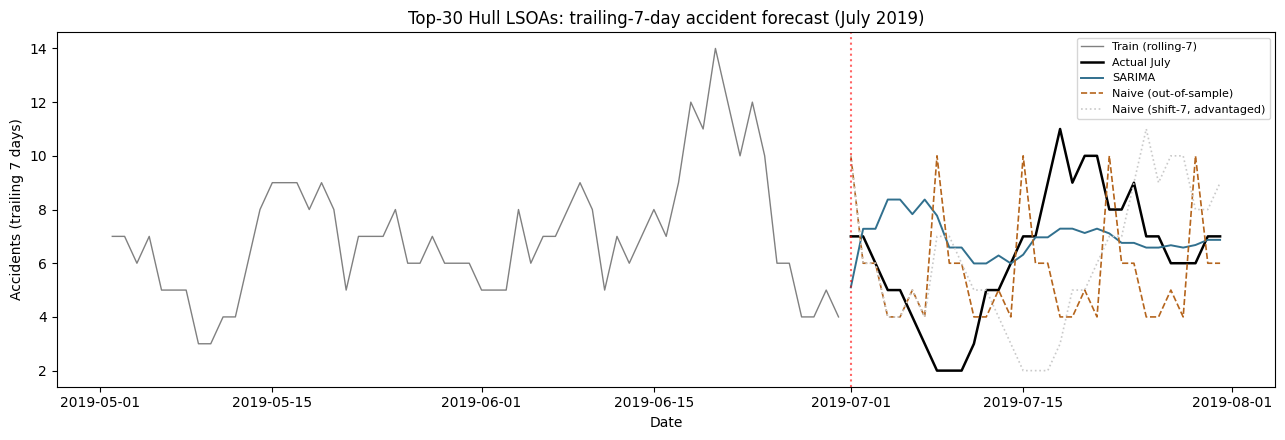

In [54]:
# 7-day rolling sum: sparse daily counts smoothed into a trailing-week signal.
roll = daily.rolling(7).sum().dropna()
roll_train = roll[roll.index.month <= 6]
roll_test  = roll[roll.index.month == 7]
print(f"Rolling-7 series: mean={roll.mean():.1f}/wk, "
      f"range={roll.min():.0f}-{roll.max():.0f}")

# SARIMA with weekly seasonality (period 7), forecasting all 31 July days ahead.
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sar = SARIMAX(roll_train, order=(1, 1, 1), seasonal_order=(1, 0, 0, 7),
                      enforce_stationarity=False, enforce_invertibility=False
                      ).fit(disp=False)
    sar_pred = sar.forecast(len(roll_test)).to_numpy()
except Exception as exc:
    print(f"SARIMA fit failed ({exc}); using mean-level fallback.")
    sar_pred = np.full(len(roll_test), float(roll_train.mean()))

# Advantaged benchmark: shift(7) peeks inside the test window (kept, labelled).
# Fair benchmark: tiling the last 7 TRAINING days, which is the same info SARIMA has. 
def naive_oos(train_s: pd.Series, test_s: pd.Series, period: int = 7) -> np.ndarray:
    """Out-of-sample seasonal-naive: repeat the final `period` training values."""
    last = train_s.to_numpy()[-period:]
    tiled = np.tile(last, int(np.ceil(len(test_s) / period)))[:len(test_s)]
    return tiled

naive_oos_pred = naive_oos(roll_train, roll_test)
naive_peek_pred = roll.shift(7).reindex(roll_test.index).to_numpy()

# Proving the "peeking" benchmark's source.
_peek_src = roll_test.index - pd.Timedelta(days=7)
_n_peek = int((_peek_src >= roll_test.index.min()).sum())
print(f"\n'shift(7)' benchmark draws {_n_peek} of its {len(roll_test)} values "
      f"from inside the July test window (i.e. it is not a true out-of-sample "
      f"forecast).")

m_sar = metrics(roll_test.values, sar_pred)
m_oos = metrics(roll_test.values, naive_oos_pred)
m_pk  = metrics(roll_test.values, naive_peek_pred)
print("\nJuly forecast accuracy on the trailing-7-day target:")
print(f"  SARIMA (31-day-ahead)            : {m_sar}")
print(f"  Naive, out-of-sample (fair)      : {m_oos}")
print(f"  Naive, shift(7) (ADVANTAGED)     : {m_pk}")
print("\n SARIMA is scored against the FAIR benchmark. The advantaged one is "
      "shown to test whether peeking even helps: if it scores no better, the "
      "July observations it reads are mostly noise, which is itself a measure "
      "of how little signal the daily series carries.")

# Plot of training tail and July forecast vs actual.
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(roll_train.index[-60:], roll_train.values[-60:],
        color="grey", lw=1, label="Train (rolling-7)")
ax.plot(roll_test.index, roll_test.values, color="black", lw=1.8, label="Actual July")
ax.plot(roll_test.index, sar_pred, color="#31708E", lw=1.4, label="SARIMA")
ax.plot(roll_test.index, naive_oos_pred, color="#B5651D", ls="--", lw=1.2,
        label="Naive (out-of-sample)")
ax.plot(roll_test.index, naive_peek_pred, color="#C9C9C9", ls=":", lw=1.2,
        label="Naive (shift-7, advantaged)")
ax.axvline(pd.Timestamp("2019-07-01"), color="red", ls=":", alpha=0.6)

ax.set(title="Top-30 Hull LSOAs: trailing-7-day accident forecast (July 2019)",
       xlabel="Date", ylabel="Accidents (trailing 7 days)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("time_series_weekly_daily.png", dpi=150, bbox_inches="tight")
plt.show()


## Section 8: Conclusions, Limitations & Recommendations

### Section 8.0: Key figures, generated from the live analysis

Every number quoted in the written report is printed below straight from the
objects created above, rather than transcribed by hand. Transcription is how a
report and its notebook drift apart: a threshold changes, the code is re-run,
and a figure in the prose quietly becomes false. Reading them out of the
notebook state makes that impossible.


In [55]:
# Single source of truth for every figure quoted in the report.
def _fmt(x, dp=1):
    return "n/a" if x is None else f"{x:,.{dp}f}"

print()
print("KEY FIGURES FROM THE ANALYSIS:")
print()

print("\n Data & cleaning -")
print(f"  Accidents loaded (2017-2020)     : {len(accidents):,}")
print(f"  2019 accidents                   : {len(acc_2019):,}")
print(f"  Valid LSOA codes                 : "
      f"{accidents['lsoa_of_accident_location'].notna().mean():.1%}")
print(f"  Apriori transactions retained    : {len(trans):,} of {len(acc_2019):,} "
      f"({len(trans)/len(acc_2019):.1%})")
print(f"  Severe base rate (2019, GB)      : {base_rate:.1%}")

print("\n Q1: temporal -")
print(f"  Hour-of-day non-uniform          : chi2={chisquare(hour_counts.values)[0]:,.0f}, "
      f"w={np.sqrt(chisquare(hour_counts.values)[0] / hour_counts.sum()):.2f}")
_wf = (acc_2019["date_parsed"].dropna().dt.normalize().drop_duplicates()
       .dt.day_name().value_counts().reindex(DAY_ORDER).values.astype(float))
_wf = _wf * day_counts.values.sum() / _wf.sum()
print(f"  Day-of-week non-uniform          : chi2={chisquare(day_counts.values, f_exp=_wf)[0]:,.0f}, "
      f"w={np.sqrt(chisquare(day_counts.values, f_exp=_wf)[0] / day_counts.sum()):.2f}")
print(f"  Motorcycle records banded        : {len(moto_time):,}")
print(f"  Pedestrian casualties (2019)     : {len(ped_time):,}")
print(f"  Under-16 share @15:00 (weekday)  : {pm_share:.1%} (n={pm_n:,})")
print(f"  Under-16 share @08:00 (weekday)  : {am_share:.1%} (n={am_n:,})")
print(f"  Under-16 share, other hours      : {oth_share:.1%} (n={oth_n:,})")

print("\n Q2: severity -")
_top = severe.iloc[0]
print(f"  Top severity rule                : {_top['conditions']}")
print(f"    support/confidence/lift        : {_top['support']:.3f} / "
      f"{_top['confidence']:.1%} / {_top['lift']:.2f}")
print(f"    share of all severe accidents  : {_top['severe_share']:.1%}")
_wide = prone.loc[prone["severe_share"].idxmax()]
print(f"  Widest-coverage rule, lift>=1.2  : {_wide['conditions']}")
print(f"    lift / share of all severe     : {_wide['lift']:.2f} / "
      f"{_wide['severe_share']:.1%}")
_bot = severe.iloc[-1]
print(f"  Most protective rule             : {_bot['conditions']}")
print(f"    support/confidence/lift        : {_bot['support']:.3f} / "
      f"{_bot['confidence']:.1%} / {_bot['lift']:.2f}")
for _name, _m in [("Logistic regression", logit), ("Gradient boosting", gbt)]:
    _p = _m.predict_proba(X_te)[:, 1]
    print(f"  {_name:<33}: ROC-AUC={roc_auc_score(y_te, _p):.3f}, "
          f"PR-AUC={average_precision_score(y_te, _p):.3f} "
          f"(PR baseline {y_te.mean():.3f})")

print("\n Q3: spatial -")
print(f"  Regional accidents (Humberside)  : {len(region):,}")
print(f"  K-Means k / silhouette           : {best_k} / {sil[best_k]:.2f}")
print(f"  DBSCAN eps / hotspots / noise    : {EPS} m / {len(hotspots)} / "
      f"{(db.labels_ == MISSING).mean():.0%}")
if hotspots.empty:
    print("  Largest hotspot                  : none (DBSCAN found no clusters)")
else:
    print(f"  Largest hotspot                  : {hotspots.iloc[0]['district']} "
          f"({int(hotspots.iloc[0]['accidents'])} accidents, "
          f"{hotspots.iloc[0]['severe_pct']:.1f}% severe)")
print(f"  Hotspot vs background severity   : chi2={hot_chi2:,.1f}, "
      f"p={hot_p:.3g}, V={hot_v:.2f}")
print(f"  Boundary-invariant (Hull+ER)     : {boundary_invariant}")

print("\n Q4: weekly forecasting -")
print(res_df.to_string())
print("\n  Fixed vs AIC-selected order:")
print(tuned_df.to_string(index=False))
print(f"  Ljung-Box (Humberside, lag 10)   : p={lb_p:.3f}")

print("\n Q5: LSOA-day forecasting -")
print(f"  Top-30 cut-off / ties            : {cutoff} accidents / {n_tied} tied")
print(f"  Daily series mean / zero-days    : {daily.mean():.2f} per day / "
      f"{(daily == 0).mean():.0%}")
print(f"  Direct daily SARIMA MAE          : {mae_sar:.3f} "
      f"(constant {mae_mean:.3f}, climatology {mae_dow:.3f})")


def _metrics_line(label: str, m: dict) -> str:
    """One aligned row per model, so the block reads as a table not a dict."""
    return (f"  {label:<33}: MAE {m['MAE']:.2f}, RMSE {m['RMSE']:.2f}, "
            f"MAPE {m['MAPE%']:.1f}%")


print(_metrics_line("Rolling-7 SARIMA", m_sar))
print(_metrics_line("Rolling-7 naive (fair, OOS)", m_oos))
print(_metrics_line("Rolling-7 naive (advantaged)", m_pk))
print()



KEY FIGURES FROM THE ANALYSIS:


 Data & cleaning -
  Accidents loaded (2017-2020)     : 461,352
  2019 accidents                   : 117,536
  Valid LSOA codes                 : 95.0%
  Apriori transactions retained    : 110,222 of 117,536 (93.8%)
  Severe base rate (2019, GB)      : 21.5%

 Q1: temporal -
  Hour-of-day non-uniform          : chi2=41,890, w=0.60
  Day-of-week non-uniform          : chi2=1,441, w=0.11
  Motorcycle records banded        : 16,889
  Pedestrian casualties (2019)     : 21,770
  Under-16 share @15:00 (weekday)  : 53.8% (n=2,046)
  Under-16 share @08:00 (weekday)  : 49.2% (n=1,685)
  Under-16 share, other hours      : 18.8% (n=12,932)

 Q2: severity -
  Top severity rule                : area_rural, road_single-cway, speed_speed60, surface_dry
    support/confidence/lift        : 0.024 / 35.9% / 1.67
    share of all severe accidents  : 4.1%
  Widest-coverage rule, lift>=1.2  : area_rural
    lift / share of all severe     : 1.23 / 10.8%
  Most protective ru

### Section 8.1: Key findings

- **Q1: When.** Accidents cluster significantly by hour and by day (both
  chi-square goodness-of-fit tests reject uniformity at p < 0.001), and the
  effect sizes rank the two patterns: the hourly effect is large (w = 0.60)
  while the daily one is small (w = 0.11), peaking at commuter hours and on
  Fridays. Motorcycle timing depends on engine size
  (chi-square independence, p < 0.001; V = 0.11 hourly, 0.06 daily, small but
  systematic): small (<=125cc) bikes follow the weekday
  commuter cycle, while large (>500cc) bikes lean toward daytime and weekend
  leisure use. Pedestrian casualties show a distinct **mid-afternoon (~3pm)
  peak**, and casualty age *tests* the school-run reading rather than assuming
  it: under-16s make up over half of weekday pedestrian casualties at 15:00
  against under a fifth across all other hours (p < 0.001). The same age
  signature appears at 08:00, so the school run is bimodal, but only the
  afternoon leg produces a casualty-count peak, the morning leg being absorbed
  into the wider commuter maximum.

- **Q2: How severe.** Rules were mined across **both** lift tails, so conditions
  that raise *and* lower severity are reported rather than only the former.
  *Severity-prone:* **rural + 60 mph + single-carriageway + dry**, at a
  confidence well above the ~21.5% base rate, with fine weather and daylight in
  closely ranked variants. *Protective:* **urban + daylight** (lift 0.83). The two
  tails are mirror images of one mechanism: severity is driven by high-speed,
  low-forgiveness roads in *benign* conditions, while adverse weather raises
  accident frequency but not per-accident severity. The leading rules are stable
  when 'unknown' codes are retained as categories instead of dropped, so the
  finding does not rest on that cleaning choice. A **severity classifier** on the
  same features (Section 4.4) confirms the direction; its strongest
  coefficients recover the same conditions the rules ranked highest, by an
  independent route, but its modest AUC shows these variables locate *where
  risk concentrates* without predicting *which* accident will be serious. That
  distinction is what separates an infrastructure recommendation, which the data
  support, from a targeting tool, which they do not. Enrichment is not reach,
  and Section 4.2 separates the two along a nested chain of antecedents: the
  top rule covers only **4.1% of all severe accidents**, relaxing it as far as
  60 mph alone buys just 6.0%, and rural roads taken on their own reach 10.8%
  at a much weaker lift of 1.23. The targeting these rules support is precise
  but narrow, and a recommendation built on them should claim no more than
  that.

- **Q3: Where.** K-Means (k chosen by silhouette) recovers the population
  centres either side of the Humber; DBSCAN isolates a small set of dense
  hotspots against a large diffuse rural background. Each hotspot is resolved to
  its district, size and severity mix in Section 5.1, and the pattern
  corroborates Q2 from the spatial side: the 12 hotspots compress 35% of the
  region's accidents into a small fraction of its area at a *below-average*
  severe rate (16.0% vs 19.1% regionally), while the diffuse remaining 65% runs
  at 20.8%. That gap is tested rather than asserted (chi-square on hotspot
  versus background, p = 0.006), and the effect size is the honest reading of
  it: V = 0.06, a reliable difference but a small one. Frequency and severity are separate geographies, and the largest
  hotspot, Hull, 378 accidents, is among the least severe at 16.7%. The hotspot count is eps-sensitive (1 at
  the ~129 m k-distance knee, 9 at 250 m, 12 at 500 m), but that structure is
  robust. So is the finding itself: Section 5.2 re-runs the whole pipeline on
  the narrower Hull and East Riding filter (n = 1,475) and the split survives
  (17.3% inside the hotspots against 21.3% outside), so this is a property of
  the data rather than of where the regional boundary was drawn.

- **Q4: Forecasting forces.** Under the seasonal-naive benchmark, error rises as
  force volume falls (Metropolitan -> West Midlands -> Humberside): baseline
  forecastability tracks the series' signal-to-noise ratio. SARIMA's gain over
  that benchmark is uneven, large for Humberside, slight for the Metropolitan,
  and negative for the West Midlands. Re-tuning the order per force by AIC does not rescue the West Midlands: the
  AIC-selected order forecasts essentially identically (15.1% vs 15.0% MAPE) and
  still loses to the seasonal naive, even though the fixed order carries no AIC
  support there. Tuning helps Humberside (12.2% to 11.5%) but is marginally worse for the
  Metropolitan (6.3% to 6.4%), so it is not that AIC selection is useless, it is
  that no order rescues the West Midlands. That force's result is a property of the data, not
  an unlucky order. Ljung-Box on the
  Humberside residuals shows autocorrelation the model has not captured even
  where it wins. Exact figures are printed in Section 8.0.

- **Q5: Forecasting hotspots.** The top-30 selection is not as clean as the
  brief implies: 25 LSOAs sit strictly above the cut-off of 2 accidents and 21
  tie at it for the 5 remaining places. Any rule for breaking that tie is
  arbitrary, and it is *load-bearing*, the series built from a different tie-break
  correlates only r=0.897 with this one. The rule is therefore declared (count
  descending, then LSOA code ascending) rather than left to row order, and
  Section 7 re-runs all three of Section 7.1's criteria on both selections.
  The substantive finding is **tie-invariant**: neither selection shows weekly
  structure, and the forecast is near-flat in both (dispersion ~ 2% of the
  observed series'), so no daily dynamics are recovered either way. The 10%
  margin indicator does flip (2.8% strict, 13.9% inclusive), but diagnosably:
  SARIMA barely moves (-0.009 MAE) while the constant benchmark degrades (+0.109)
  on the noisier 46-area series. A better-placed flat line is not a better model,
  and this is precisely why three criteria were declared rather than one. At the
  LSOA-day grain, counts are near-Poisson sparse (~ 1 per day, 36% of days zero). Direct modelling was *tested* rather
  than assumed to fail, and it fails on both counts: a day-of-week climatology
  (MAE 0.99) performs worse than a flat mean (0.92), so there is no weekly
  structure for a period-7 model to exploit; and the direct SARIMA's edge over
  that constant is 2.8% (0.896 vs 0.922), far below the 10% threshold declared in
  Section 7.1, on a forecast whose dispersion is a small fraction of the observed
  series'. The edge is level estimation, not forecasting.

  On the 7-day rolling target the picture is different, and the difference is
  instructive. SARIMA (MAE 1.96) beats a *fair* out-of-sample naive (2.58) by
  24%, above the declared threshold. This does **not** overturn the conclusion,
  for a reason Section 7.1 anticipates: the rolling sum induces MA(6) dependence
  by construction, so a model fitted to it is substantially tracking the
  smoother rather than the traffic. The direct daily model, which has no such
  scaffolding, finds nothing. The rolling gain is therefore evidence that a
  *slow-moving level* is estimable, not that daily dynamics are recoverable,
  and at 1.96 against a mean of ~7.5 accidents/week it is a 26% error, too
  coarse to act on. Predictability effectively bottoms out at this resolution.

  A note on the benchmarks. The `shift(7)` naive that reads July actuals (2.81)
  scored *worse* than the fair one that does not (2.58). Peeking did not help it,
  because at this sparsity the observations it steals are mostly noise, which is
  itself a measure of how little signal the daily series carries.

**Synthesis.** Accident *frequency* is exposure-driven (commuter hours, Fridays,
urban density), whereas *severity* is driven by road type and speed,
concentrating on rural 60 mph single carriageways, and, symmetrically, thinning
on urban 30 mph roads in daylight. Three independent methods agree on this split:
association rules, a severity classifier, and the spatial severity profile of the
DBSCAN hotspots. What the split does not carry is scale: the conditions that
concentrate severity account for a single-figure percentage of severe outcomes,
so they locate where to intervene without being the whole of the problem. Forecastability tracks the signal-to-noise ratio of the series:
reliable at police-force scale, degrading toward the historical mean at LSOA-day
granularity, where the series retains a level but no recoverable dynamics.

### Section 8.2: Limitations

- Only 2017-2018 history means the 52-week seasonal cycle is observed just
  twice, so SARIMA's seasonal term is weakly identified. A fixed order was held
  across forces for like-for-like comparison; Section 6.1 shows this order is
  not the best-fitting model for any force by AIC, though Section 6.2 shows
  AIC-selected orders do not forecast better, and for the West Midlands forecast
  worse.
- Residual autocorrelation remains in the Humberside model (Ljung-Box p = 0.017),
  so its forecast intervals are optimistic, and its point forecasts should be
  read as indicative rather than calibrated.
- Weeks straddling a year boundary are excluded from both the training and test
  sets (Section 6), costing roughly one week at each boundary. This is preferred
  to the alternative, which silently placed a 2018 day inside the 2019 test set.
- Q5's rolling-7 target induces MA(6) dependence by construction (Section 7.1),
  so its error metrics are not comparable with the raw daily ones and the fitted
  ARIMA order partly describes the smoother rather than the traffic.
- Q5's top-30 boundary falls in the middle of a 21-way tie at 2 accidents, so
  the identity of 5 of the 30 areas is arbitrary and the resulting daily series
  is sensitive to it (r=0.897 against the inclusive alternative). The tie-break
  is declared, and the substantive conclusion is verified to hold under both
  selections. The 10% margin indicator alone does not hold under both, and is
  reported with its diagnosis rather than suppressed: it moves because the
  constant benchmark degrades on a noisier series, not because the model
  improves. Had the dispersion criterion not been declared in advance, that
  movement could have been read as a discovery.
- Q5 percentage errors (MAPE) are inflated by low denominators; MAE is the
  fairer accuracy measure at low counts.
- The regional sample (Q3) makes DBSCAN's exact hotspot count eps-sensitive,
  though the broad structure (few dense cores, diffuse rural spread) is robust.
- Two fields were imputed from within-record information after hold-out
  validation (Section 2.1); the remaining high-sentinel fields encode *not
  applicable* rather than *unknown* and were correctly left alone. Rows carrying
  a recorded 'unknown' code in a mined field are still excluded from Q2, and
  that exclusion is not random; unknowns concentrate in accidents the police
  did not attend, so a small selection bias remains. Section 4's sensitivity
  check shows the leading rules survive, retaining them as categories.
- Motorcycle records that could not be banded were dropped. The engine-capacity
  recovery attempted on the type-97 records succeeded for none of them, because
  the field is sentinel-coded on every one; the electric motorcycles have no cc
  equivalent and were excluded on principle. A small selection bias cannot be
  ruled out.
- Clustering uses easting/northing without population or road-length exposure
  denominators, so hotspots reflect counts, not per-capita risk. A recommendation
  to target them is a recommendation to target where casualties are, which is not
  identical to where risk per journey is highest.
- STATS19 records only *reported* injury accidents; damage-only and unreported
  incidents are excluded, so all figures under-represent total road risk.

## Section 9: Recommendations to the Department for Transport

Each recommendation names the analysis that supports it, and, as important,
the analysis is allowed to constrain how far the recommendation goes.

1. **Prioritise rural single-carriageway 60 mph roads for engineering
   intervention, not enforcement in poor weather.** Q2's strongest severity
   association is rural + 60 mph + single-carriageway in *dry, fine, daylight*
   conditions, and the severity classifier independently recovers the same
   drivers. The size of the prize belongs next to the target: that condition
   set accounts for 4.1% of all severe accidents and rural roads as a whole for
   10.8% (Section 4.2), so this is precision work on a defined part of the
   network, not a measure that moves the national total by itself. Severe outcomes are concentrated where impact speeds are high, and
   the roadside is unforgiving, not where conditions are adverse. Average-speed
   cameras, verge treatment and central hatching on these roads target the
   mechanism; wet-weather campaigns target frequency, which is a different
   problem with a different answer.

2. **Fund school-run pedestrian measures on the afternoon leg specifically.**
   Q1 shows a 15:00 pedestrian casualty peak in which under-16s are the majority
   of casualties, against under a fifth at other hours. The morning leg carries
   the same age signature but is masked in the raw counts by the commuter
   maximum, so a measure timed only to the visible peak would miss half the
   exposure. School Streets closures and crossing patrols should cover both
   legs, and the afternoon one is where the casualty reduction is largest.

3. **Tailor motorcycle measures by machine class.**

   Smaller machines (≤125cc) cluster in weekday commuting and delivery,
   larger machines (>500cc) in weekend leisure riding, so interventions should
   differ accordingly.

4. **Target the named Humberside hotspots for local schemes, while recognising
   they are frequency, not severity, hotspots.** Section 5.1 resolves each
   DBSCAN cluster to a district, count and severity mix, and the below-average
   severe rate inside them is reliable though small (V = 0.06, p = 0.006) and
   survives the narrower regional definition (Section 5.2). These urban cores carry
   the bulk of regional accidents at a *below-average* severe rate: they are the
   right target for junction redesign and casualty-volume reduction, and the
   wrong target for a fatality-reduction programme, which Q2 places on the rural
   network instead.

5. **Set force-level resourcing from forecasts; do not attempt LSOA-day
   deployment from them.** Q4 forecasts weekly counts at force scale with error
   in the single-digit-to-low-teens percent range. Q5 demonstrates that this
   skill does not survive the zoom to LSOA-day: there is no exploitable weekly
   structure and no model beats the historical mean by a practical margin.
   Predictive deployment tools sold at that granularity should be treated as
   claiming more than this data can support.

6. **Improve STATS19 collection at source, targeting the fields that block
   analysis.** The LSOA code is sentinel-coded on a share of records and
   silently behaves as a valid area unless explicitly cleaned; `speed_limit` and
   `road_surface_conditions` were recoverable here only because they correlate
   with other recorded fields, which will not always hold. Because unknown codes
   concentrate in accidents the police did not attend, the missingness is not
   random and biases exactly the severity analysis that policy depends on.


## References

Works cited in this notebook's narrative. Method and software references for
the techniques used (Apriori, DBSCAN, silhouette, SARIMA, scikit-learn,
statsmodels, mlxtend) are given in full in the accompanying written report.

Burnham, K.P. and Anderson, D.R. (2004) 'Multimodel inference: understanding
AIC and BIC in model selection', *Sociological Methods & Research*, 33(2),
pp. 261-304.

Cohen, J. (1988) *Statistical Power Analysis for the Behavioral Sciences*. 2nd
edn. Hillsdale, NJ: Lawrence Erlbaum Associates.

Department for Transport (2011) *Instructions for the Completion of Road
Accident Reports from non-CRASH Sources (STATS20)*. London: Department for
Transport.

Department for Transport (2023) *Road Safety Data* [accident_data_v1.0.0_2023.db].
Available at: https://www.data.gov.uk/dataset/cb7ae6f0-4be6-4935-9277-47e5ce24a11f/road-accidents-safety-data
(Accessed: 10 July 2026).